# Step 1: Dataset Inspection

### Dataset File Inventory

In [2]:
from pathlib import Path
from collections import Counter

# -----------------------------------
# 1. Dataset location
# -----------------------------------

PIPELINE_ROOT = Path(
    "/Users/praise/Developer/vocal-harmonization/"
    "datasets/mtg-jamendo/"
    "melody-chord-extraction-pipeline"
)

OUTPUT_DIR = PIPELINE_ROOT / "outputs"

assert OUTPUT_DIR.is_dir(), (
    f"Output directory not found: {OUTPUT_DIR}"
)


# -----------------------------------
# 2. Required files per song
# -----------------------------------

REQUIRED_FILES = {
    "melody": "melody/combined.json",
    "beats": "beats/beats.json",
    "chords": "roman/submission.json",
    "key": "key.json"
}


# -----------------------------------
# 3. Find all processed track folders
# -----------------------------------

track_folders = sorted(
    folder
    for folder in OUTPUT_DIR.glob("track_*")
    if folder.is_dir()
)


# -----------------------------------
# 4. Check file availability
# -----------------------------------

complete_tracks = []
incomplete_tracks = []

missing_counts = Counter()

for track_folder in track_folders:

    missing = []

    for name, relative_path in REQUIRED_FILES.items():

        file_path = track_folder / relative_path

        if not file_path.is_file():
            missing.append(name)
            missing_counts[name] += 1

    if not missing:
        complete_tracks.append(track_folder)

    else:
        incomplete_tracks.append({
            "track_id": track_folder.name,
            "missing": missing
        })


# -----------------------------------
# 5. Display results
# -----------------------------------

print("PHASE 2 — DATASET INVENTORY")
print("--------------------------------")

print("Total track folders:", len(track_folders))
print("Complete tracks:", len(complete_tracks))
print("Incomplete tracks:", len(incomplete_tracks))


print("\nMISSING FILE COUNTS")
print("--------------------------------")

for name in REQUIRED_FILES:
    print(f"{name}: {missing_counts[name]}")


print("\nSAMPLE INCOMPLETE TRACKS")
print("--------------------------------")

for track in incomplete_tracks[:5]:
    print(track)

PHASE 2 — DATASET INVENTORY
--------------------------------
Total track folders: 1156
Complete tracks: 872
Incomplete tracks: 284

MISSING FILE COUNTS
--------------------------------
melody: 284
beats: 284
chords: 284
key: 284

SAMPLE INCOMPLETE TRACKS
--------------------------------
{'track_id': 'track_1072437', 'missing': ['melody', 'beats', 'chords', 'key']}
{'track_id': 'track_1072570', 'missing': ['melody', 'beats', 'chords', 'key']}
{'track_id': 'track_1072571', 'missing': ['melody', 'beats', 'chords', 'key']}
{'track_id': 'track_1072572', 'missing': ['melody', 'beats', 'chords', 'key']}
{'track_id': 'track_1072573', 'missing': ['melody', 'beats', 'chords', 'key']}


### Inspect JSON Structure and Data Availability

In [3]:
import json
import pandas as pd


# -----------------------------------
# 1. Helper function
# -----------------------------------

def count_items(data, field):

    if isinstance(data, dict):
        items = data.get(field)

    elif isinstance(data, list):
        items = data

    else:
        return None

    if isinstance(items, list):
        return len(items)

    return None


# -----------------------------------
# 2. Inspect completed tracks
# -----------------------------------

audit_rows = []
parse_errors = []

sample_data = None

for track_folder in complete_tracks:

    row = {
        "track_id": track_folder.name
    }

    loaded = {}

    for name, relative_path in REQUIRED_FILES.items():

        file_path = track_folder / relative_path

        try:
            with open(file_path, "r") as f:
                loaded[name] = json.load(f)

        except (OSError, ValueError) as e:

            parse_errors.append({
                "track_id": track_folder.name,
                "file": name,
                "error": str(e)
            })

            loaded[name] = None

    # Count extracted events
    row["melody_notes"] = count_items(
        loaded["melody"], "notes"
    )

    row["beats"] = count_items(
        loaded["beats"], "beats"
    )

    row["chord_events"] = count_items(
        loaded["chords"], "events"
    )

    row["all_json_readable"] = all(
        value is not None
        for value in loaded.values()
    )

    audit_rows.append(row)

    # Save one example for inspecting structure
    if sample_data is None and row["all_json_readable"]:
        sample_data = loaded
        sample_track = track_folder.name


# -----------------------------------
# 3. Create audit table
# -----------------------------------

audit_df = pd.DataFrame(audit_rows)


print("JSON CONTENT AUDIT")
print("--------------------------------")

print("Tracks inspected:", len(audit_df))

print(
    "Tracks with readable JSON:",
    audit_df["all_json_readable"].sum()
)

print("JSON reading errors:", len(parse_errors))


# -----------------------------------
# 4. Check empty extracted data
# -----------------------------------

print("\nEMPTY DATA CHECK")
print("--------------------------------")

for column in [
    "melody_notes",
    "beats",
    "chord_events"
]:

    print(
        f"{column}:",
        (audit_df[column] == 0).sum(),
        "empty tracks"
    )

    print(
        f"{column}:",
        audit_df[column].isna().sum(),
        "tracks with unrecognized structure"
    )


# -----------------------------------
# 5. Basic statistics
# -----------------------------------

print("\nEXTRACTED DATA STATISTICS")
print("--------------------------------")

display(
    audit_df[
        ["melody_notes", "beats", "chord_events"]
    ].describe()
)


# -----------------------------------
# 6. Inspect one JSON example
# -----------------------------------

print("\nSAMPLE JSON STRUCTURE")
print("--------------------------------")

print("Track:", sample_track)

for name, data in sample_data.items():

    print(f"\n{name.upper()}")

    if isinstance(data, dict):

        print("Top-level fields:", list(data.keys()))

        field = {
            "melody": "notes",
            "beats": "beats",
            "chords": "events",
            "key": None
        }[name]

        if field and isinstance(data.get(field), list):

            items = data[field]

            if items and isinstance(items[0], dict):
                print(
                    "First event fields:",
                    list(items[0].keys())
                )

    else:
        print("Data type:", type(data).__name__)


# -----------------------------------
# 7. Display reading errors
# -----------------------------------

if parse_errors:

    print("\nSAMPLE JSON ERRORS")

    display(
        pd.DataFrame(parse_errors).head(10)
    )

JSON CONTENT AUDIT
--------------------------------
Tracks inspected: 872
Tracks with readable JSON: 872
JSON reading errors: 0

EMPTY DATA CHECK
--------------------------------
melody_notes: 0 empty tracks
melody_notes: 0 tracks with unrecognized structure
beats: 0 empty tracks
beats: 0 tracks with unrecognized structure
chord_events: 0 empty tracks
chord_events: 0 tracks with unrecognized structure

EXTRACTED DATA STATISTICS
--------------------------------


,melody_notes,beats,chord_events
count,872.000000,872.000000,872.000000
mean,487.666284,421.572248,69.243119
std,288.379744,242.477339,45.331746
min,13.000000,34.000000,1.000000
25%,330.000000,272.000000,34.000000
50%,440.500000,371.000000,67.000000
75%,587.000000,498.000000,97.000000
max,2730.000000,2613.000000,399.000000



SAMPLE JSON STRUCTURE
--------------------------------
Track: track_0000382

MELODY
Top-level fields: ['schema_version', 'track_id', 'mtg_track_id', 'method', 'source_mp3', 'source_fingerprint', 'time_origin', 'pitch_unit', 'duration_sec', 'notes', 'selection']
First event fields: ['onset_sec', 'offset_sec', 'midi_pitch', 'midi_pitch_rounded', 'velocity', 'source']

BEATS
Top-level fields: ['schema_version', 'track_id', 'mtg_track_id', 'source_mp3', 'source_fingerprint', 'method', 'model_revision', 'time_origin', 'duration_sec', 'median_beat_period_sec', 'median_beat_rate_bpm', 'downbeat_lab_times_sec', 'downbeat_lab_matches_beat_positions', 'beats']
First event fields: ['beat_index', 'time_sec', 'beat_in_bar', 'bar_index', 'meter_numerator', 'meter_denominator', 'is_downbeat']

CHORDS
Top-level fields: ['schema_version', 'mapping_version', 'track_id', 'mtg_track_id', 'source_mp3', 'source_fingerprint', 'time_origin', 'duration_sec', 'vocabulary', 'chord_json_sha256', 'key_json_sha256

### Validate Melody, Beat, and Chord Timing

In [4]:
import json
import numpy as np
import pandas as pd


# -----------------------------------
# 1. Helper functions
# -----------------------------------

def valid_number(value):

    return (
        isinstance(value, (int, float))
        and not isinstance(value, bool)
        and np.isfinite(value)
    )


def valid_interval(start, end):

    return (
        valid_number(start)
        and valid_number(end)
        and 0 <= start < end
    )


# -----------------------------------
# 2. Inspect timing information
# -----------------------------------

timing_rows = []

for track_folder in complete_tracks:

    # Load JSON files
    with open(track_folder / REQUIRED_FILES["melody"]) as f:
        melody = json.load(f)

    with open(track_folder / REQUIRED_FILES["beats"]) as f:
        beats_data = json.load(f)

    with open(track_folder / REQUIRED_FILES["chords"]) as f:
        chords = json.load(f)

    notes = melody["notes"]
    beats = beats_data["beats"]
    events = chords["events"]

    duration = melody.get("duration_sec")

    # -----------------------------------
    # A. Check melody note durations
    # -----------------------------------

    invalid_notes = sum(
        not valid_interval(
            n.get("onset_sec"),
            n.get("offset_sec")
        )
        for n in notes
    )

    # -----------------------------------
    # B. Check chord event durations
    # -----------------------------------

    invalid_chords = sum(
        not valid_interval(
            c.get("start_sec"),
            c.get("end_sec")
        )
        for c in events
    )

    # -----------------------------------
    # C. Check chronological beat order
    # -----------------------------------

    beat_times = [
        b.get("time_sec")
        for b in beats
    ]

    invalid_beat_times = sum(
        not valid_number(t) or t < 0
        for t in beat_times
    )

    beat_order_errors = sum(
        t2 <= t1
        for t1, t2 in zip(
            beat_times[:-1],
            beat_times[1:]
        )
        if valid_number(t1)
        and valid_number(t2)
    )

    # -----------------------------------
    # D. Check recording boundaries
    # -----------------------------------

    # Allow a 0.5-second tolerance
    TOLERANCE = 0.5

    notes_outside = 0
    chords_outside = 0

    if valid_number(duration):

        notes_outside = sum(
            valid_interval(
                n.get("onset_sec"),
                n.get("offset_sec")
            )
            and n["offset_sec"] > duration + TOLERANCE
            for n in notes
        )

        chords_outside = sum(
            valid_interval(
                c.get("start_sec"),
                c.get("end_sec")
            )
            and c["end_sec"] > duration + TOLERANCE
            for c in events
        )

    # -----------------------------------
    # E. Check duration consistency
    # -----------------------------------

    durations = [
        melody.get("duration_sec"),
        beats_data.get("duration_sec"),
        chords.get("duration_sec")
    ]

    valid_durations = [
        d for d in durations
        if valid_number(d)
    ]

    duration_mismatch = (
        len(valid_durations) != 3
        or max(valid_durations) - min(valid_durations) > 1.0
    )

    # -----------------------------------
    # F. Save results
    # -----------------------------------

    timing_rows.append({
        "track_id": track_folder.name,
        "invalid_notes": invalid_notes,
        "invalid_chords": invalid_chords,
        "invalid_beat_times": invalid_beat_times,
        "beat_order_errors": beat_order_errors,
        "notes_outside": notes_outside,
        "chords_outside": chords_outside,
        "duration_mismatch": duration_mismatch
    })


# -----------------------------------
# 3. Create results table
# -----------------------------------

timing_df = pd.DataFrame(timing_rows)

issue_columns = [
    "invalid_notes",
    "invalid_chords",
    "invalid_beat_times",
    "beat_order_errors",
    "notes_outside",
    "chords_outside",
    "duration_mismatch"
]


# -----------------------------------
# 4. Summary
# -----------------------------------

print("TIMESTAMP INTEGRITY AUDIT")
print("--------------------------------")

print("Tracks inspected:", len(timing_df))

print("\nTRACKS AFFECTED BY EACH ISSUE")
print("--------------------------------")

for column in issue_columns:

    affected = (timing_df[column] > 0).sum()

    print(f"{column}: {affected}")


# -----------------------------------
# 5. Overall summary
# -----------------------------------

timing_df["has_timing_issue"] = (
    timing_df[issue_columns].gt(0).any(axis=1)
)

print("\nOVERALL RESULTS")
print("--------------------------------")

print(
    "Tracks without detected timing issues:",
    (~timing_df["has_timing_issue"]).sum()
)

print(
    "Tracks with at least one timing issue:",
    timing_df["has_timing_issue"].sum()
)


# -----------------------------------
# 6. Inspect problematic tracks
# -----------------------------------

problematic_tracks = timing_df[
    timing_df["has_timing_issue"]
]

print("\nSAMPLE PROBLEMATIC TRACKS")
print("--------------------------------")

display(problematic_tracks.head(10))

TIMESTAMP INTEGRITY AUDIT
--------------------------------
Tracks inspected: 872

TRACKS AFFECTED BY EACH ISSUE
--------------------------------
invalid_notes: 0
invalid_chords: 0
invalid_beat_times: 0
beat_order_errors: 0
notes_outside: 0
chords_outside: 0
duration_mismatch: 0

OVERALL RESULTS
--------------------------------
Tracks without detected timing issues: 872
Tracks with at least one timing issue: 0

SAMPLE PROBLEMATIC TRACKS
--------------------------------


,track_id,invalid_notes,invalid_chords,invalid_beat_times,beat_order_errors,notes_outside,chords_outside,duration_mismatch,has_timing_issue


### Analyze Time Signatures and Beat Structure

In [5]:
import json
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Initialize counters
# -----------------------------------

meter_song_counts = Counter()
meter_beat_counts = Counter()
beats_per_bar = Counter()
downbeat_positions = Counter()

tracks_with_meter_changes = []


# -----------------------------------
# 2. Analyze each song
# -----------------------------------

for track_folder in complete_tracks:

    with open(
        track_folder / REQUIRED_FILES["beats"]
    ) as f:
        data = json.load(f)

    beats = data["beats"]

    # Extract detected time signatures
    meters = [
        (
            b["meter_numerator"],
            b["meter_denominator"]
        )
        for b in beats
    ]

    unique_meters = set(meters)

    # Number of songs containing each meter
    meter_song_counts.update(unique_meters)

    # Number of beats associated with each meter
    meter_beat_counts.update(meters)

    # Songs containing multiple meters
    if len(unique_meters) > 1:
        tracks_with_meter_changes.append(
            track_folder.name
        )

    # Count detected beats in each bar
    bars = Counter(
        b["bar_index"]
        for b in beats
    )

    # Exclude first and last bars
    # because they may be incomplete
    bar_ids = sorted(bars)

    for bar_id in bar_ids[1:-1]:
        beats_per_bar[bars[bar_id]] += 1

    # Check downbeat positions
    for b in beats:

        if b["is_downbeat"]:
            downbeat_positions[
                b["beat_in_bar"]
            ] += 1


# -----------------------------------
# 3. Time signature distribution
# -----------------------------------

meter_df = pd.DataFrame([
    {
        "Time Signature": f"{n}/{d}",
        "Songs": meter_song_counts[(n, d)],
        "Beats": count
    }
    for (n, d), count
    in meter_beat_counts.most_common()
])

print("TIME SIGNATURE DISTRIBUTION")
print("--------------------------------")

display(meter_df)


# -----------------------------------
# 4. Beats per bar
# -----------------------------------

print("\nDETECTED BEATS PER BAR")
print("--------------------------------")

for count, bars in sorted(
    beats_per_bar.items()
):
    print(f"{count} beats: {bars} bars")


# -----------------------------------
# 5. Downbeat positions
# -----------------------------------

print("\nDOWNBEAT POSITIONS")
print("--------------------------------")

print(dict(sorted(
    downbeat_positions.items()
)))


# -----------------------------------
# 6. Meter changes
# -----------------------------------

print("\nMETER CHANGES")
print("--------------------------------")

print(
    "Tracks with multiple detected meters:",
    len(tracks_with_meter_changes)
)

print(
    "Examples:",
    tracks_with_meter_changes[:10]
)

TIME SIGNATURE DISTRIBUTION
--------------------------------


,Time Signature,Songs,Beats
0,4/4,704,298031
1,2/4,114,32204
2,6/8,30,26363
3,3/4,26,10537
4,3/8,50,153
5,1/8,129,129
6,5/8,17,90
7,7/8,11,77
8,9/8,3,27



DETECTED BEATS PER BAR
--------------------------------
1 beats: 1049 bars
2 beats: 16172 bars
3 beats: 4003 bars
4 beats: 72855 bars
5 beats: 20 bars
6 beats: 4334 bars
7 beats: 3 bars
9 beats: 3 bars

DOWNBEAT POSITIONS
--------------------------------
{1: 100171}

METER CHANGES
--------------------------------
Tracks with multiple detected meters: 207
Examples: ['track_0000383', 'track_0000386', 'track_0000388', 'track_0000389', 'track_0000395', 'track_0002171', 'track_0021984', 'track_0031425', 'track_0031427', 'track_0031429']


### Check suspicious meters

In [6]:
from collections import Counter, defaultdict
import json
import pandas as pd

SUSPICIOUS_METERS = {
    (1, 8), (3, 8), (5, 8),
    (7, 8), (9, 8)
}

rows = []

for folder in complete_tracks:

    with open(folder / REQUIRED_FILES["beats"]) as f:
        data = json.load(f)

    beats = data["beats"]

    # Group detected beats by bar
    bars = defaultdict(list)

    for beat in beats:
        bars[beat["bar_index"]].append(beat)

    bar_ids = sorted(bars)

    first_bar = bar_ids[0]
    last_bar = bar_ids[-1]

    for bar_id, bar_beats in bars.items():

        meters = [
            (
                b["meter_numerator"],
                b["meter_denominator"]
            )
            for b in bar_beats
        ]

        # Most common meter within the bar
        meter = Counter(meters).most_common(1)[0][0]

        if meter not in SUSPICIOUS_METERS:
            continue

        rows.append({
            "Track": folder.name,
            "Meter": f"{meter[0]}/{meter[1]}",
            "Beat count": len(bar_beats),
            "At song boundary": (
                bar_id == first_bar
                or bar_id == last_bar
            )
        })


suspicious_df = pd.DataFrame(rows)

print("SUSPICIOUS METER ANALYSIS")
print("--------------------------------")

summary = suspicious_df.groupby("Meter").agg(
    Total_bars=("Track", "size"),
    Boundary_bars=("At song boundary", "sum"),
    Interior_bars=(
        "At song boundary",
        lambda x: (~x).sum()
    )
)

display(summary)

SUSPICIOUS METER ANALYSIS
--------------------------------


,Total_bars,Boundary_bars,Interior_bars
Meter,,,
1/8,129,121,8
3/8,51,39,12
5/8,18,13,5
7/8,11,10,1
9/8,3,0,3


### Inspect Key JSON Structure

In [7]:
import json
from pprint import pprint

# Select one completed track
track = complete_tracks[0]

# Load key information
with open(track / REQUIRED_FILES["key"]) as f:
    key_data = json.load(f)

# Load chord information for comparison
with open(track / REQUIRED_FILES["chords"]) as f:
    chord_data = json.load(f)


print("KEY ESTIMATION STRUCTURE")
print("--------------------------------")

print("Track:", track.name)

print("\nMELODY KEY FIELDS")
print("--------------------------------")

melody_key = key_data.get("melody_key", {})

print(list(melody_key.keys()))

print("\nMELODY KEY INFORMATION")
print("--------------------------------")

pprint(melody_key, depth=3)


print("\nCHORD KEY INFORMATION")
print("--------------------------------")

print("Key source:", chord_data.get("key_source"))

pprint(chord_data.get("key"), depth=3)

KEY ESTIMATION STRUCTURE
--------------------------------
Track: track_0000382

MELODY KEY FIELDS
--------------------------------
['method', 'note_count', 'phrase_end_count', 'pitch_class_duration_sec_capped_at_2', 'selected', 'candidates', 'confidence', 'top_score_gap']

MELODY KEY INFORMATION
--------------------------------
{'candidates': [{'mode': 'major',
                 'profile_correlation': 0.80722,
                 'score': 0.82246,
                 'tonic': 'C',
                 'tonic_ending_fraction': 0.19048,
                 'tonic_pc': 0},
                {'mode': 'major',
                 'profile_correlation': 0.66955,
                 'score': 0.68098,
                 'tonic': 'F',
                 'tonic_ending_fraction': 0.14286,
                 'tonic_pc': 5},
                {'mode': 'major',
                 'profile_correlation': 0.62167,
                 'score': 0.64453,
                 'tonic': 'G',
                 'tonic_ending_fraction': 0.28571,
    

### Analyze Key Agreement Across All Songs

In [8]:
import json
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Collect key information
# -----------------------------------

key_rows = []
missing_comparisons = []
reading_errors = []

for track_folder in complete_tracks:

    comparison_path = (
        track_folder / "key_comparison.json"
    )

    if not comparison_path.is_file():
        missing_comparisons.append(track_folder.name)
        continue

    try:
        with open(comparison_path) as f:
            data = json.load(f)

    except (OSError, ValueError) as e:
        reading_errors.append({
            "track_id": track_folder.name,
            "error": str(e)
        })
        continue

    melody = data.get("melody_key") or {}
    chord = data.get("chord_key") or {}
    chord_selected = chord.get("selected") or {}

    key_rows.append({
        "track_id": track_folder.name,

        # Melody estimate
        "melody_tonic": melody.get("tonic"),
        "melody_tonic_pc": melody.get("tonic_pc"),
        "melody_mode": melody.get("mode"),
        "melody_confidence": melody.get("confidence"),

        # Chord estimate
        "chord_tonic": chord_selected.get("tonic"),
        "chord_tonic_pc": chord_selected.get("tonic_pc"),
        "chord_mode": chord_selected.get("mode"),
        "chord_confidence": chord_selected.get("confidence"),

        # Diagnostic information
        "agreement": data.get("agreement"),
        "review_flag": data.get("review_flag"),
        "review_reasons": data.get("review_reasons"),

        "usable_chord_segments": chord.get(
            "usable_chord_segments"
        ),

        "chord_score_gap": chord.get(
            "top_score_gap"
        )
    })


# -----------------------------------
# 2. Create DataFrame
# -----------------------------------

key_df = pd.DataFrame(key_rows)


# -----------------------------------
# 3. File availability
# -----------------------------------

print("KEY COMPARISON AUDIT")
print("--------------------------------")

print("Complete tracks:", len(complete_tracks))
print("Comparisons loaded:", len(key_df))
print("Missing comparisons:", len(missing_comparisons))
print("Reading errors:", len(reading_errors))


# -----------------------------------
# 4. Key agreement
# -----------------------------------

print("\nKEY AGREEMENT")
print("--------------------------------")

display(
    key_df["agreement"]
    .value_counts(dropna=False)
    .rename_axis("Agreement")
    .reset_index(name="Songs")
)


# -----------------------------------
# 5. Confidence distribution
# -----------------------------------

print("\nMELODY KEY CONFIDENCE")
print("--------------------------------")

display(
    key_df["melody_confidence"]
    .value_counts(dropna=False)
)

print("\nCHORD KEY CONFIDENCE")
print("--------------------------------")

display(
    key_df["chord_confidence"]
    .value_counts(dropna=False)
)


# -----------------------------------
# 6. Major/minor distribution
# -----------------------------------

print("\nMELODY KEY MODES")
print("--------------------------------")

display(
    key_df["melody_mode"]
    .value_counts(dropna=False)
)


# -----------------------------------
# 7. Review flags
# -----------------------------------

print("\nREVIEW FLAGS")
print("--------------------------------")

display(
    key_df["review_flag"]
    .value_counts(dropna=False)
)


# -----------------------------------
# 8. Numerical statistics
# -----------------------------------

print("\nCHORD ESTIMATION STATISTICS")
print("--------------------------------")

display(
    key_df[
        [
            "usable_chord_segments",
            "chord_score_gap"
        ]
    ].describe()
)

KEY COMPARISON AUDIT
--------------------------------
Complete tracks: 872
Comparisons loaded: 872
Missing comparisons: 0
Reading errors: 0

KEY AGREEMENT
--------------------------------


,Agreement,Songs
0,agree,450
1,disagree,407
2,insufficient_evidence,15



MELODY KEY CONFIDENCE
--------------------------------


melody_confidence
high      433
low       242
medium    196
NaN         1
Name: count, dtype: int64


CHORD KEY CONFIDENCE
--------------------------------


...

melody_mode
minor    518
major    353
NaN        1
Name: count, dtype: int64


REVIEW FLAGS
--------------------------------


review_flag
True     533
False    339
Name: count, dtype: int64


CHORD ESTIMATION STATISTICS
--------------------------------


,usable_chord_segments,chord_score_gap
count,872.000000,858.000000
mean,66.732798,0.171976
std,45.215782,0.104623
min,0.000000,0.000410
25%,31.000000,0.079427
50%,64.500000,0.168600
75%,95.000000,0.256252
max,387.000000,0.404850


### Key Disagreement Analysis

In [9]:
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Classify key relationships
# -----------------------------------

def classify_key_relationship(row):

    m_pc = row["melody_tonic_pc"]
    c_pc = row["chord_tonic_pc"]

    m_mode = row["melody_mode"]
    c_mode = row["chord_mode"]

    # Missing key information
    if (
        pd.isna(m_pc)
        or pd.isna(c_pc)
        or m_mode not in ("major", "minor")
        or c_mode not in ("major", "minor")
    ):
        return "Unavailable"

    m_pc = int(m_pc)
    c_pc = int(c_pc)

    # Exact agreement
    if m_pc == c_pc and m_mode == c_mode:
        return "Same key"

    # Parallel keys: C major vs C minor
    if m_pc == c_pc and m_mode != c_mode:
        return "Parallel"

    # Relative keys: C major vs A minor
    if m_mode != c_mode:

        major_pc = (
            m_pc if m_mode == "major" else c_pc
        )

        minor_pc = (
            m_pc if m_mode == "minor" else c_pc
        )

        if (major_pc - minor_pc) % 12 == 3:
            return "Relative"

    # Fifth/fourth-related keys in same mode
    distance = (c_pc - m_pc) % 12

    if (
        m_mode == c_mode
        and distance in (5, 7)
    ):
        return "Fifth-related"

    return "Other"


# -----------------------------------
# 2. Apply classification
# -----------------------------------

key_df["relationship"] = key_df.apply(
    classify_key_relationship,
    axis=1
)


# -----------------------------------
# 3. Disagreement distribution
# -----------------------------------

disagreements = key_df[
    key_df["agreement"] == "disagree"
]

print("KEY DISAGREEMENT TYPES")
print("--------------------------------")

display(
    disagreements["relationship"]
    .value_counts()
    .rename_axis("Relationship")
    .reset_index(name="Songs")
)


# -----------------------------------
# 4. Melody confidence vs agreement
# -----------------------------------

print("\nMELODY CONFIDENCE VS AGREEMENT")
print("--------------------------------")

display(
    pd.crosstab(
        key_df["melody_confidence"].fillna("missing"),
        key_df["agreement"]
    )
)


# -----------------------------------
# 5. Chord confidence vs agreement
# -----------------------------------

print("\nCHORD CONFIDENCE VS AGREEMENT")
print("--------------------------------")

display(
    pd.crosstab(
        key_df["chord_confidence"].fillna("missing"),
        key_df["agreement"]
    )
)


# -----------------------------------
# 6. Review reasons
# -----------------------------------

review_reason_counts = Counter()

for reasons in key_df["review_reasons"]:

    if isinstance(reasons, list):
        review_reason_counts.update(reasons)


print("\nREVIEW REASONS")
print("--------------------------------")

display(
    pd.DataFrame(
        review_reason_counts.most_common(),
        columns=["Reason", "Songs"]
    )
)


# -----------------------------------
# 7. Agreement vs review flags
# -----------------------------------

print("\nAGREEMENT VS REVIEW FLAGS")
print("--------------------------------")

display(
    pd.crosstab(
        key_df["agreement"],
        key_df["review_flag"]
    )
)

KEY DISAGREEMENT TYPES
--------------------------------


,Relationship,Songs
0,Other,150
1,Fifth-related,119
2,Parallel,83
3,Relative,55



MELODY CONFIDENCE VS AGREEMENT
--------------------------------


agreement,agree,disagree,insufficient_evidence
melody_confidence,,,
high,289,143,1
low,76,155,11
medium,85,109,2
missing,0,0,1



CHORD CONFIDENCE VS AGREEMENT
--------------------------------


agreement,agree,disagree,insufficient_evidence
chord_confidence,,,
high,341,254,1
low,57,71,0
medium,52,82,0
missing,0,0,14



REVIEW REASONS
--------------------------------


,Reason,Songs
0,key_disagreement,407
1,low_melody_key_confidence,242
2,low_chord_key_confidence,128
3,insufficient_evidence,15



AGREEMENT VS REVIEW FLAGS
--------------------------------


review_flag,False,True
agreement,,
agree,339,111
disagree,0,407
insufficient_evidence,0,15


In [10]:
import pandas as pd

# -----------------------------------
# 1. Combined confidence categories
# -----------------------------------

key_df["confidence_pair"] = (
    key_df["melody_confidence"].fillna("missing")
    + " / "
    + key_df["chord_confidence"].fillna("missing")
)

print("COMBINED CONFIDENCE VS AGREEMENT")
print("--------------------------------")

display(
    pd.crosstab(
        key_df["confidence_pair"],
        key_df["agreement"]
    )
)


# -----------------------------------
# 2. Both estimators highly confident
# -----------------------------------

both_high = key_df[
    (key_df["melody_confidence"] == "high")
    & (key_df["chord_confidence"] == "high")
]

print("\nBOTH ESTIMATORS HIGH CONFIDENCE")
print("--------------------------------")

print("Total songs:", len(both_high))

display(
    both_high["agreement"].value_counts()
)


# -----------------------------------
# 3. Investigate 'Other' disagreements
# -----------------------------------

other = key_df[
    (key_df["agreement"] == "disagree")
    & (key_df["relationship"] == "Other")
].copy()

other["mode_relationship"] = (
    other["melody_mode"]
    + " → "
    + other["chord_mode"]
)

print("\nOTHER DISAGREEMENTS BY MODE")
print("--------------------------------")

display(
    other["mode_relationship"].value_counts()
)


# -----------------------------------
# 4. Examine concrete disagreements
# -----------------------------------

print("\nSAMPLE HIGH-CONFIDENCE DISAGREEMENTS")
print("--------------------------------")

examples = key_df[
    (key_df["agreement"] == "disagree")
    & (key_df["melody_confidence"] == "high")
    & (key_df["chord_confidence"] == "high")
]

display(
    examples[
        [
            "track_id",
            "melody_tonic",
            "melody_mode",
            "chord_tonic",
            "chord_mode",
            "relationship",
            "usable_chord_segments"
        ]
    ].head(15)
)

COMBINED CONFIDENCE VS AGREEMENT
--------------------------------


agreement,agree,disagree,insufficient_evidence
confidence_pair,,,
high / high,239,82,0
high / low,21,32,0
high / medium,29,29,0
high / missing,0,0,1
low / high,43,101,0
low / low,22,27,0
low / medium,11,27,0
low / missing,0,0,11
medium / high,59,71,0



BOTH ESTIMATORS HIGH CONFIDENCE
--------------------------------
Total songs: 321


agreement
agree       239
disagree     82
Name: count, dtype: int64


OTHER DISAGREEMENTS BY MODE
--------------------------------


mode_relationship
minor → major    66
major → minor    64
minor → minor    12
major → major     8
Name: count, dtype: int64


SAMPLE HIGH-CONFIDENCE DISAGREEMENTS
--------------------------------


,track_id,melody_tonic,melody_mode,chord_tonic,chord_mode,relationship,usable_chord_segments
30,track_0031429,Eb,minor,Ab,minor,Fifth-related,81
37,track_0031436,E,major,Db,minor,Relative,65
48,track_0046036,D,major,A,major,Fifth-related,55
68,track_0072837,Gb,minor,D,major,Other,65
77,track_0076661,D,major,A,major,Fifth-related,60
82,track_0086249,Gb,minor,Db,minor,Fifth-related,7
92,track_0086280,A,minor,D,minor,Fifth-related,79
115,track_0205093,Eb,major,C,minor,Relative,42
132,track_0212204,Db,minor,A,major,Other,70
135,track_0215561,A,minor,A,major,Parallel,7


### Select High-Confidence Songs and Inspect Melody

In [11]:
import json
import numpy as np
import pandas as pd

# -----------------------------------
# 1. Select high-confidence songs
# -----------------------------------

selected_ids = set(
    key_df.loc[
        (key_df["agreement"] == "agree")
        & (key_df["melody_confidence"] == "high")
        & (key_df["chord_confidence"] == "high"),
        "track_id"
    ]
)

selected_tracks = [
    folder
    for folder in complete_tracks
    if folder.name in selected_ids
]

print("Selected songs:", len(selected_tracks))


# -----------------------------------
# 2. Analyze melody notes
# -----------------------------------

melody_rows = []

for folder in selected_tracks:

    with open(folder / REQUIRED_FILES["melody"]) as f:
        data = json.load(f)

    notes = data["notes"]

    pitches = [
        n["midi_pitch_rounded"]
        for n in notes
    ]

    durations = [
        n["offset_sec"] - n["onset_sec"]
        for n in notes
    ]

    melody_rows.append({
        "track_id": folder.name,
        "note_count": len(notes),
        "min_pitch": min(pitches),
        "max_pitch": max(pitches),
        "mean_pitch": np.mean(pitches),
        "median_duration": np.median(durations),
        "short_notes": sum(d < 0.05 for d in durations),
        "long_notes": sum(d > 4.0 for d in durations)
    })


# -----------------------------------
# 3. Display statistics
# -----------------------------------

melody_df = pd.DataFrame(melody_rows)

print("\nMELODY QUALITY STATISTICS")
print("--------------------------------")

display(
    melody_df.drop(columns="track_id").describe()
)

print("\nTOTAL SUSPICIOUS NOTE COUNTS")
print("--------------------------------")

print(
    "Very short notes (< 0.05s):",
    melody_df["short_notes"].sum()
)

print(
    "Very long notes (> 4s):",
    melody_df["long_notes"].sum()
)

print("\nSONGS WITH FEWEST NOTES")
print("--------------------------------")

display(
    melody_df.nsmallest(10, "note_count")
)

Selected songs: 239

MELODY QUALITY STATISTICS
--------------------------------


,note_count,min_pitch,max_pitch,mean_pitch,median_duration,short_notes,long_notes
count,239.000000,239.000000,239.000000,239.000000,239.000000,239.0,239.000000
mean,502.476987,54.715481,85.460251,69.948925,0.302172,0.0,0.523013
std,235.653870,6.004429,8.154334,4.088226,0.115689,0.0,1.305488
min,44.000000,41.000000,71.000000,59.454333,0.140000,0.0,0.000000
25%,348.000000,51.000000,80.000000,67.554601,0.240110,0.0,0.000000
50%,459.000000,55.000000,84.000000,69.685824,0.280000,0.0,0.000000
75%,617.000000,58.500000,88.000000,72.253819,0.330210,0.0,0.000000
max,1198.000000,71.000000,109.000000,84.883838,1.279690,0.0,10.000000



TOTAL SUSPICIOUS NOTE COUNTS
--------------------------------
Very short notes (< 0.05s): 0
Very long notes (> 4s): 125

SONGS WITH FEWEST NOTES
--------------------------------


,track_id,note_count,min_pitch,max_pitch,mean_pitch,median_duration,short_notes,long_notes
117,track_0893404,44,69,96,81.795455,0.394800,0,0
237,track_1067707,50,55,91,72.200000,0.490105,0,1
2,track_0000394,86,56,86,67.848837,0.880000,0,4
116,track_0893399,88,54,87,68.522727,0.549945,0,1
162,track_0989067,106,46,106,73.094340,0.520050,0,1
0,track_0000390,108,59,86,78.851852,0.820000,0,1
154,track_0975527,111,67,88,74.459459,0.445310,0,1
171,track_1028809,117,67,91,82.538462,0.705210,0,2
1,track_0000391,123,55,83,71.495935,0.370000,0,0
238,track_1071484,144,57,106,75.243056,1.279690,0,0


### Melody Coverage and Gap Analysis

In [12]:
import json
import numpy as np
import pandas as pd

coverage_rows = []

for folder in selected_tracks:

    with open(folder / REQUIRED_FILES["melody"]) as f:
        data = json.load(f)

    notes = data["notes"]
    song_duration = data["duration_sec"]

    # Collect note intervals
    intervals = sorted([
        (
            max(0, n["onset_sec"]),
            min(song_duration, n["offset_sec"])
        )
        for n in notes
    ])

    # Merge overlapping note intervals
    merged = []

    for start, end in intervals:

        if not merged or start > merged[-1][1]:
            merged.append([start, end])

        else:
            merged[-1][1] = max(
                merged[-1][1], end
            )

    # Total time containing melody
    melody_duration = sum(
        end - start
        for start, end in merged
    )

    coverage = (
        melody_duration / song_duration
        if song_duration > 0 else 0
    )

    # Calculate melody-free gaps
    gaps = []

    previous_end = 0

    for start, end in merged:
        gaps.append(start - previous_end)
        previous_end = end

    # Include gap after last note
    gaps.append(song_duration - previous_end)

    coverage_rows.append({
        "track_id": folder.name,
        "song_duration": song_duration,
        "note_count": len(notes),
        "melody_coverage": coverage,
        "longest_gap_sec": max(gaps),
        "gaps_over_8s": sum(g > 8 for g in gaps),
        "gaps_over_15s": sum(g > 15 for g in gaps)
    })


coverage_df = pd.DataFrame(coverage_rows)

print("MELODY COVERAGE STATISTICS")
print("--------------------------------")

display(
    coverage_df.drop(columns="track_id").describe()
)


print("\nSONGS BY MELODY COVERAGE")
print("--------------------------------")

for threshold in [0.25, 0.50, 0.75]:

    count = (
        coverage_df["melody_coverage"] >= threshold
    ).sum()

    print(
        f"Coverage >= {threshold:.0%}: {count} songs"
    )


print("\nSONGS WITH LARGE MELODY GAPS")
print("--------------------------------")

print(
    "At least one gap > 8 seconds:",
    (coverage_df["gaps_over_8s"] > 0).sum()
)

print(
    "At least one gap > 15 seconds:",
    (coverage_df["gaps_over_15s"] > 0).sum()
)


print("\nSONGS WITH LOWEST COVERAGE")
print("--------------------------------")

display(
    coverage_df.nsmallest(
        10, "melody_coverage"
    )
)

MELODY COVERAGE STATISTICS
--------------------------------


,song_duration,note_count,melody_coverage,longest_gap_sec,gaps_over_8s,gaps_over_15s
count,239.000000,239.000000,239.000000,239.000000,239.000000,239.000000
mean,231.809514,502.476987,0.791597,9.476243,0.489540,0.154812
std,81.213357,235.653870,0.091824,10.135390,0.808889,0.416427
min,39.048005,44.000000,0.502655,0.450000,0.000000,0.000000
25%,176.598674,348.000000,0.732177,3.908333,0.000000,0.000000
50%,223.978027,459.000000,0.795360,6.479229,0.000000,0.000000
75%,272.123164,617.000000,0.855626,11.256125,1.000000,0.000000
max,553.770862,1198.000000,0.996939,65.580232,6.000000,2.000000



SONGS BY MELODY COVERAGE
--------------------------------
Coverage >= 25%: 239 songs
Coverage >= 50%: 239 songs
Coverage >= 75%: 167 songs

SONGS WITH LARGE MELODY GAPS
--------------------------------
At least one gap > 8 seconds: 87
At least one gap > 15 seconds: 32

SONGS WITH LOWEST COVERAGE
--------------------------------


,track_id,song_duration,note_count,melody_coverage,longest_gap_sec,gaps_over_8s,gaps_over_15s
115,track_0889236,553.770862,800,0.502655,65.580232,3,2
27,track_0086270,132.666735,190,0.505300,40.030000,1,1
188,track_1037231,261.007823,324,0.539330,51.907823,2,1
131,track_0947022,100.056009,154,0.539812,30.079690,1,1
23,track_0076658,223.978027,302,0.540057,20.159900,4,1
107,track_0856980,400.000000,492,0.541690,35.260000,4,2
88,track_0628409,301.986667,331,0.571271,40.170000,2,2
155,track_0976519,312.000000,538,0.573008,16.640000,1,1
90,track_0628412,287.880000,541,0.600563,60.129900,2,1
123,track_0915581,167.880000,345,0.616658,7.480000,0,0


### Window-Level Melody Coverage

In [13]:
import json
import numpy as np
import pandas as pd
from collections import defaultdict


WINDOW_BARS = 8

SUPPORTED_METERS = {
    (2, 4), (3, 4), (4, 4), (6, 8)
}


# -----------------------------------
# 1. Calculate melody coverage in a window
# -----------------------------------

def window_melody_stats(notes, start, end):

    intervals = []

    for note in notes:

        s = max(start, note["onset_sec"])
        e = min(end, note["offset_sec"])

        if s < e:
            intervals.append((s, e))

    intervals.sort()

    merged = []

    for s, e in intervals:

        if not merged or s > merged[-1][1]:
            merged.append([s, e])
        else:
            merged[-1][1] = max(
                merged[-1][1], e
            )

    melody_time = sum(
        e - s for s, e in merged
    )

    coverage = melody_time / (end - start)

    gaps = []
    previous_end = start

    for s, e in merged:
        gaps.append(s - previous_end)
        previous_end = e

    gaps.append(end - previous_end)

    return {
        "note_count": len(intervals),
        "coverage": coverage,
        "longest_gap": max(gaps)
    }


# -----------------------------------
# 2. Analyze eight-bar windows
# -----------------------------------

window_rows = []

for folder in selected_tracks:

    with open(folder / REQUIRED_FILES["melody"]) as f:
        melody = json.load(f)

    with open(folder / REQUIRED_FILES["beats"]) as f:
        beat_data = json.load(f)

    beats = beat_data["beats"]
    notes = melody["notes"]

    bars = defaultdict(list)

    for beat in beats:
        bars[beat["bar_index"]].append(beat)

    # Identify complete bars in supported meters
    valid_bars = set()

    for bar_id, bar_beats in bars.items():

        meters = {
            (
                b["meter_numerator"],
                b["meter_denominator"]
            )
            for b in bar_beats
        }

        if len(meters) != 1:
            continue

        numerator, denominator = next(iter(meters))

        positions = {
            b["beat_in_bar"] for b in bar_beats
        }

        if (
            (numerator, denominator) in SUPPORTED_METERS
            and len(bar_beats) == numerator
            and positions == set(range(1, numerator + 1))
        ):
            valid_bars.add(bar_id)

    # Build consecutive runs of valid bars
    runs = []
    current_run = []

    for bar_id in sorted(bars):

        if bar_id in valid_bars:

            if current_run and bar_id != current_run[-1] + 1:
                runs.append(current_run)
                current_run = []

            current_run.append(bar_id)

        elif current_run:
            runs.append(current_run)
            current_run = []

    if current_run:
        runs.append(current_run)

    all_beat_times = sorted(
        b["time_sec"] for b in beats
    )

    # Non-overlapping eight-bar windows
    for run in runs:

        for i in range(0, len(run) - WINDOW_BARS + 1, WINDOW_BARS):

            window_bars = run[i:i + WINDOW_BARS]

            first_beat = min(
                bars[window_bars[0]],
                key=lambda b: b["time_sec"]
            )

            last_beat = max(
                bars[window_bars[-1]],
                key=lambda b: b["time_sec"]
            )

            start = first_beat["time_sec"]

            # End at the following beat boundary
            next_times = [
                t for t in all_beat_times
                if t > last_beat["time_sec"]
            ]

            if not next_times:
                continue

            end = next_times[0]

            stats = window_melody_stats(
                notes, start, end
            )

            window_rows.append({
                "track_id": folder.name,
                "start_sec": start,
                "end_sec": end,
                **stats
            })


# -----------------------------------
# 3. Summarize
# -----------------------------------

window_df = pd.DataFrame(window_rows)

print("WINDOW-LEVEL MELODY ANALYSIS")
print("--------------------------------")

print("Total windows:", len(window_df))
print("Songs with windows:", window_df["track_id"].nunique())

display(
    window_df[
        ["note_count", "coverage", "longest_gap"]
    ].describe()
)


# -----------------------------------
# 4. Preliminary filtering
# -----------------------------------

window_df["usable"] = (
    (window_df["coverage"] >= 0.50)
    & (window_df["note_count"] >= 10)
    & (window_df["longest_gap"] <= 8)
)

usable_windows = window_df[
    window_df["usable"]
]

print("\nPRELIMINARY USABLE WINDOWS")
print("--------------------------------")

print("Usable windows:", len(usable_windows))

print(
    "Usable songs:",
    usable_windows["track_id"].nunique()
)

print(
    "Rejected windows:",
    (~window_df["usable"]).sum()
)


# -----------------------------------
# 5. Reasons for rejection
# -----------------------------------

print("\nQUALITY CONDITIONS NOT MET")
print("--------------------------------")

print(
    "Coverage below 50%:",
    (window_df["coverage"] < 0.50).sum()
)

print(
    "Fewer than 10 notes:",
    (window_df["note_count"] < 10).sum()
)

print(
    "Gap longer than 8 seconds:",
    (window_df["longest_gap"] > 8).sum()
)

WINDOW-LEVEL MELODY ANALYSIS
--------------------------------
Total windows: 3191
Songs with windows: 239


,note_count,coverage,longest_gap
count,3191.000000,3191.000000,3191.000000
mean,34.577562,0.811527,1.477235
std,16.141562,0.177449,2.250774
min,0.000000,0.000000,0.000000
25%,23.000000,0.741099,0.410000
50%,32.000000,0.849172,0.900000
75%,44.000000,0.935901,1.709945
max,110.000000,1.000000,32.680000



PRELIMINARY USABLE WINDOWS
--------------------------------
Usable windows: 2986
Usable songs: 239
Rejected windows: 205

QUALITY CONDITIONS NOT MET
--------------------------------
Coverage below 50%: 165
Fewer than 10 notes: 112
Gap longer than 8 seconds: 69


### Chord Vocabulary and Distribution

In [14]:
import json
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Initialize counters
# -----------------------------------

chord_counts = Counter()
chord_durations = Counter()

family_counts = Counter()
mapping_counts = Counter()

chord_rows = []


# -----------------------------------
# 2. Analyze selected songs
# -----------------------------------

for folder in selected_tracks:

    with open(
        folder / REQUIRED_FILES["chords"]
    ) as f:
        data = json.load(f)

    events = data["events"]

    total_chord_time = 0
    no_chord_time = 0

    for event in events:

        label = event.get("basic_label") or "MISSING"
        family = event.get("family") or "MISSING"

        status = (
            event.get("mapping_status")
            or "MISSING"
        )

        duration = (
            event["end_sec"]
            - event["start_sec"]
        )

        # Count chord occurrences
        chord_counts[label] += 1

        # Accumulate chord durations
        chord_durations[label] += duration

        # Count chord families
        family_counts[family] += 1

        # Count mapping statuses
        mapping_counts[status] += 1

        total_chord_time += duration

        if label == "N":
            no_chord_time += duration

    chord_rows.append({
        "track_id": folder.name,
        "chord_events": len(events),
        "total_chord_time": total_chord_time,
        "no_chord_time": no_chord_time,
        "no_chord_fraction": (
            no_chord_time / total_chord_time
            if total_chord_time > 0 else 0
        )
    })


# -----------------------------------
# 3. Chord vocabulary
# -----------------------------------

print("CHORD VOCABULARY ANALYSIS")
print("--------------------------------")

print("Songs analyzed:", len(selected_tracks))

print(
    "Unique chord labels:",
    len(chord_counts)
)

print(
    "Total chord events:",
    sum(chord_counts.values())
)


# -----------------------------------
# 4. Most frequent chord labels
# -----------------------------------

total_events = sum(chord_counts.values())
total_duration = sum(chord_durations.values())

chord_distribution = pd.DataFrame([
    {
        "Chord": label,
        "Events": count,
        "Event %": 100 * count / total_events,
        "Duration %": (
            100 * chord_durations[label]
            / total_duration
        )
    }
    for label, count in chord_counts.items()
])

chord_distribution = (
    chord_distribution
    .sort_values(
        "Duration %",
        ascending=False
    )
)

print("\nMOST COMMON CHORD LABELS")
print("--------------------------------")

display(chord_distribution.head(20))


# -----------------------------------
# 5. Chord families
# -----------------------------------

print("\nCHORD FAMILY DISTRIBUTION")
print("--------------------------------")

display(
    pd.DataFrame(
        family_counts.most_common(),
        columns=["Family", "Events"]
    )
)


# -----------------------------------
# 6. Mapping statuses
# -----------------------------------

print("\nCHORD MAPPING STATUS")
print("--------------------------------")

display(
    pd.DataFrame(
        mapping_counts.most_common(),
        columns=["Mapping Status", "Events"]
    )
)


# -----------------------------------
# 7. Rare chord classes
# -----------------------------------

rare_chords = {
    label: count
    for label, count in chord_counts.items()
    if count < 10
}

print("\nRARE CHORD LABELS")
print("--------------------------------")

print(
    "Classes with fewer than 10 events:",
    len(rare_chords)
)

print(rare_chords)


# -----------------------------------
# 8. Per-song chord statistics
# -----------------------------------

chord_df = pd.DataFrame(chord_rows)

print("\nPER-SONG CHORD STATISTICS")
print("--------------------------------")

display(
    chord_df.drop(
        columns="track_id"
    ).describe()
)

CHORD VOCABULARY ANALYSIS
--------------------------------
Songs analyzed: 239
Unique chord labels: 59
Total chord events: 18323

MOST COMMON CHORD LABELS
--------------------------------


,Chord,Events,Event %,Duration %
7,i:MIN,3620,19.756590,31.003760
1,I:MAJ,2182,11.908530,16.616304
11,bVI:MAJ,2200,12.006767,9.094278
6,IV:MAJ,1944,10.609616,8.330073
12,iv:MIN,1336,7.291382,5.833523
0,N,593,3.236370,5.738226
3,V:MAJ,1434,7.826229,5.087132
9,bVII:MAJ,1296,7.073078,4.358123
8,bIII:MAJ,994,5.424876,3.339140
4,vi:MIN,533,2.908912,2.086065



CHORD FAMILY DISTRIBUTION
--------------------------------


,Family,Events
0,MAJ,10461
1,MIN,6546
2,N,593
3,DOM7,593
4,HDIM7,47
5,SUS4,43
6,DIM,33
7,AUG,6
8,DIM7,1



CHORD MAPPING STATUS
--------------------------------


,Mapping Status,Events
0,mapped,17730
1,no_chord,593



RARE CHORD LABELS
--------------------------------
Classes with fewer than 10 events: 21
{'VII:DOM7': 4, 'III:DOM7': 6, 'VI:DOM7': 3, 'bvi:HDIM7': 1, 'iii:DIM': 3, '#iv:DIM': 8, 'v:HDIM7': 1, 'bii:HDIM7': 2, 'vii:HDIM7': 2, 'bvi:DIM7': 1, 'bvi:MIN': 6, 'bvi:DIM': 2, 'bVII:SUS4': 5, 'VII:AUG': 3, 'vi:DIM': 3, 'biii:HDIM7': 4, 'biii:DIM': 2, 'I:SUS4': 6, 'IV:SUS4': 1, 'ii:DIM': 4, 'bVI:AUG': 3}

PER-SONG CHORD STATISTICS
--------------------------------


,chord_events,total_chord_time,no_chord_time,no_chord_fraction
count,239.000000,239.000000,239.000000,239.000000
mean,76.665272,231.821255,13.302427,0.059006
std,41.082067,81.212935,22.425136,0.084290
min,3.000000,39.060000,0.020000,0.000084
25%,48.000000,176.600000,3.935000,0.017642
50%,72.000000,223.980000,7.780000,0.035808
75%,103.000000,272.125000,14.935000,0.070437
max,206.000000,553.770000,287.630000,0.760986


### Chord Duration and Transition Quality

In [15]:
import json
import numpy as np
import pandas as pd


chord_quality_rows = []

GAP_TOLERANCE = 0.05  # 50 milliseconds


# -----------------------------------
# 1. Inspect chord segments
# -----------------------------------

for folder in selected_tracks:

    with open(folder / REQUIRED_FILES["chords"]) as f:
        data = json.load(f)

    events = sorted(
        data["events"],
        key=lambda e: e["start_sec"]
    )

    durations = [
        e["end_sec"] - e["start_sec"]
        for e in events
    ]

    # Separate actual chords from N
    valid_chords = [
        e for e in events
        if e["basic_label"] != "N"
    ]

    no_chords = [
        e for e in events
        if e["basic_label"] == "N"
    ]

    # -----------------------------------
    # 2. Check adjacent segments
    # -----------------------------------

    gaps = []
    overlaps = []
    repeated_labels = 0
    chord_changes = 0

    for previous, current in zip(
        events[:-1], events[1:]
    ):

        difference = (
            current["start_sec"]
            - previous["end_sec"]
        )

        if difference > GAP_TOLERANCE:
            gaps.append(difference)

        elif difference < -GAP_TOLERANCE:
            overlaps.append(abs(difference))

        # Count consecutive identical labels
        if (
            previous["basic_label"]
            == current["basic_label"]
        ):
            repeated_labels += 1

        # Count changes between actual chords
        if (
            previous["basic_label"] != "N"
            and current["basic_label"] != "N"
            and previous["basic_label"]
                != current["basic_label"]
        ):
            chord_changes += 1

    # -----------------------------------
    # 3. Calculate statistics
    # -----------------------------------

    non_n_durations = [
        e["end_sec"] - e["start_sec"]
        for e in valid_chords
    ]

    n_durations = [
        e["end_sec"] - e["start_sec"]
        for e in no_chords
    ]

    total_duration = sum(durations)

    chord_quality_rows.append({
        "track_id": folder.name,
        "chord_events": len(events),

        "median_chord_duration": (
            np.median(non_n_durations)
            if non_n_durations else np.nan
        ),

        "max_chord_duration": (
            max(non_n_durations)
            if non_n_durations else 0
        ),

        "short_chords": sum(
            d < 0.1 for d in non_n_durations
        ),

        "long_chords": sum(
            d > 8 for d in non_n_durations
        ),

        "gaps": len(gaps),
        "overlaps": len(overlaps),

        "repeated_labels": repeated_labels,
        "chord_changes": chord_changes,

        "longest_n": (
            max(n_durations)
            if n_durations else 0
        ),

        "n_fraction": (
            sum(n_durations) / total_duration
            if total_duration > 0 else 0
        )
    })


# -----------------------------------
# 4. Create DataFrame
# -----------------------------------

chord_quality_df = pd.DataFrame(
    chord_quality_rows
)


print("CHORD SEGMENT QUALITY")
print("--------------------------------")

display(
    chord_quality_df.drop(
        columns="track_id"
    ).describe()
)


# -----------------------------------
# 5. Potential quality issues
# -----------------------------------

print("\nQUALITY ISSUE SUMMARY")
print("--------------------------------")

for column in [
    "short_chords",
    "long_chords",
    "gaps",
    "overlaps",
    "repeated_labels"
]:

    print(
        f"{column}:",
        chord_quality_df[column].sum(),
        "total occurrences"
    )

    print(
        "  Affected songs:",
        (chord_quality_df[column] > 0).sum()
    )


# -----------------------------------
# 6. Excessive N regions
# -----------------------------------

print("\nNO-CHORD REGION ANALYSIS")
print("--------------------------------")

print(
    "Songs with >25% N:",
    (chord_quality_df["n_fraction"] > 0.25).sum()
)

print(
    "Songs with >50% N:",
    (chord_quality_df["n_fraction"] > 0.50).sum()
)


print("\nSONGS WITH MOST NO-CHORD TIME")
print("--------------------------------")

display(
    chord_quality_df.nlargest(
        10, "n_fraction"
    )[
        [
            "track_id",
            "chord_events",
            "n_fraction",
            "longest_n",
            "chord_changes"
        ]
    ]
)

CHORD SEGMENT QUALITY
--------------------------------


,chord_events,median_chord_duration,max_chord_duration,short_chords,long_chords,gaps,overlaps,repeated_labels,chord_changes,longest_n,n_fraction
count,239.000000,239.000000,239.000000,239.0,239.000000,239.0,239.0,239.000000,239.000000,239.000000,239.000000
mean,76.665272,4.472594,21.945314,0.0,3.138075,0.0,0.0,2.184100,70.443515,8.886151,0.059006
std,41.082067,18.115186,28.081198,0.0,3.267129,0.0,0.0,3.308951,40.124648,12.060806,0.084290
min,3.000000,0.800000,2.440000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.020000,0.000084
25%,48.000000,1.710000,8.065000,0.0,1.000000,0.0,0.0,0.000000,41.000000,3.350000,0.017642
50%,72.000000,2.250000,13.240000,0.0,3.000000,0.0,0.0,1.000000,67.000000,5.390000,0.035808
75%,103.000000,3.410000,23.205000,0.0,5.000000,0.0,0.0,3.000000,96.000000,9.060000,0.070437
max,206.000000,210.700000,210.700000,0.0,17.000000,0.0,0.0,22.000000,199.000000,107.530000,0.760986



QUALITY ISSUE SUMMARY
--------------------------------
short_chords: 0 total occurrences
  Affected songs: 0
long_chords: 750 total occurrences
  Affected songs: 183
gaps: 0 total occurrences
  Affected songs: 0
overlaps: 0 total occurrences
  Affected songs: 0
repeated_labels: 522 total occurrences
  Affected songs: 137

NO-CHORD REGION ANALYSIS
--------------------------------
Songs with >25% N: 7
Songs with >50% N: 2

SONGS WITH MOST NO-CHORD TIME
--------------------------------


,track_id,chord_events,n_fraction,longest_n,chord_changes
209,track_1054099,15,0.760986,107.53,1
173,track_1029125,8,0.625052,89.77,6
85,track_0618825,11,0.498311,40.05,6
1,track_0000391,21,0.392422,24.20,14
163,track_0991710,8,0.291616,23.52,2
11,track_0040620,66,0.286064,69.03,59
172,track_1028813,34,0.271040,41.54,30
117,track_0893404,17,0.236559,7.52,14
98,track_0717715,86,0.204157,37.02,74
60,track_0480227,29,0.172563,11.24,24


### Window-Level Chord Coverage

In [16]:
import json
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Get melody-rich windows
# -----------------------------------

melody_windows = window_df[
    window_df["usable"]
].copy()

folder_lookup = {
    folder.name: folder
    for folder in selected_tracks
}

chord_window_rows = []


# -----------------------------------
# 2. Analyze chord coverage per window
# -----------------------------------

for track_id, track_windows in melody_windows.groupby("track_id"):

    folder = folder_lookup[track_id]

    with open(folder / REQUIRED_FILES["chords"]) as f:
        data = json.load(f)

    events = data["events"]

    for row in track_windows.itertuples(index=False):

        start = row.start_sec
        end = row.end_sec

        window_duration = end - start

        chord_time = 0
        no_chord_time = 0

        chord_labels = set()
        label_durations = Counter()

        for event in events:

            # Calculate overlap with current window
            overlap = max(
                0,
                min(end, event["end_sec"])
                - max(start, event["start_sec"])
            )

            if overlap <= 0:
                continue

            label = event["basic_label"]

            if label == "N":
                no_chord_time += overlap

            else:
                chord_time += overlap
                chord_labels.add(label)
                label_durations[label] += overlap

        # Fraction occupied by most common chord
        dominant_fraction = (
            max(label_durations.values()) / chord_time
            if chord_time > 0 else 0
        )

        chord_window_rows.append({
            "track_id": track_id,
            "start_sec": start,
            "end_sec": end,

            "chord_coverage": chord_time / window_duration,
            "no_chord_fraction": no_chord_time / window_duration,

            "unique_chords": len(chord_labels),
            "dominant_chord_fraction": dominant_fraction
        })


# -----------------------------------
# 3. Create DataFrame
# -----------------------------------

chord_window_df = pd.DataFrame(chord_window_rows)


print("WINDOW-LEVEL CHORD ANALYSIS")
print("--------------------------------")

print("Melody-rich windows:", len(chord_window_df))

display(
    chord_window_df[
        [
            "chord_coverage",
            "no_chord_fraction",
            "unique_chords",
            "dominant_chord_fraction"
        ]
    ].describe()
)


# -----------------------------------
# 4. Chord coverage thresholds
# -----------------------------------

print("\nWINDOWS BY CHORD COVERAGE")
print("--------------------------------")

for threshold in [0.50, 0.80, 0.95]:

    count = (
        chord_window_df["chord_coverage"] >= threshold
    ).sum()

    print(
        f"Chord coverage >= {threshold:.0%}:",
        count
    )


# -----------------------------------
# 5. Chord diversity
# -----------------------------------

print("\nCHORD DIVERSITY")
print("--------------------------------")

print(
    "Windows with no actual chords:",
    (chord_window_df["unique_chords"] == 0).sum()
)

print(
    "Windows with only one chord class:",
    (chord_window_df["unique_chords"] == 1).sum()
)

print(
    "Windows with 2+ chord classes:",
    (chord_window_df["unique_chords"] >= 2).sum()
)


# -----------------------------------
# 6. Potential training candidates
# -----------------------------------

chord_window_df["chord_usable"] = (
    chord_window_df["chord_coverage"] >= 0.80
)

candidates = chord_window_df[
    chord_window_df["chord_usable"]
]

print("\nPRELIMINARY TRAINING CANDIDATES")
print("--------------------------------")

print("Candidate windows:", len(candidates))

print(
    "Songs represented:",
    candidates["track_id"].nunique()
)


# -----------------------------------
# 7. Inspect worst windows
# -----------------------------------

print("\nWINDOWS WITH LOWEST CHORD COVERAGE")
print("--------------------------------")

display(
    chord_window_df.nsmallest(
        10, "chord_coverage"
    )
)

WINDOW-LEVEL CHORD ANALYSIS
--------------------------------
Melody-rich windows: 2986


,chord_coverage,no_chord_fraction,unique_chords,dominant_chord_fraction
count,2986.000000,2986.000000,2986.000000,2986.000000
mean,0.969141,0.030859,3.406229,0.550414
std,0.136209,0.136209,1.516878,0.226968
min,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,2.000000,0.380034
50%,1.000000,0.000000,3.000000,0.507842
75%,1.000000,0.000000,4.000000,0.685049
max,1.000000,1.000000,11.000000,1.000000



WINDOWS BY CHORD COVERAGE
--------------------------------
Chord coverage >= 50%: 2921
Chord coverage >= 80%: 2845
Chord coverage >= 95%: 2741

CHORD DIVERSITY
--------------------------------
Windows with no actual chords: 31
Windows with only one chord class: 268
Windows with 2+ chord classes: 2687

PRELIMINARY TRAINING CANDIDATES
--------------------------------
Candidate windows: 2845
Songs represented: 238

WINDOWS WITH LOWEST CHORD COVERAGE
--------------------------------


,track_id,start_sec,end_sec,chord_coverage,no_chord_fraction,unique_chords,dominant_chord_fraction,chord_usable
6,track_0000391,0.01,17.33,0.0,1.0,0,0.0,False
17,track_0007391,0.01,16.06,0.0,1.0,0,0.0,False
116,track_0040620,27.08,40.50,0.0,1.0,0,0.0,False
117,track_0040620,48.71,61.89,0.0,1.0,0,0.0,False
327,track_0076660,165.15,179.95,0.0,1.0,0,0.0,False
459,track_0225363,0.41,15.57,0.0,1.0,0,0.0,False
460,track_0225363,15.57,30.65,0.0,1.0,0,0.0,False
752,track_0452751,380.24,390.48,0.0,1.0,0,0.0,False
1026,track_0606118,0.12,12.60,0.0,1.0,0,0.0,False
1052,track_0618825,0.01,16.10,0.0,1.0,0,0.0,False


### Chord Boundary Alignment

In [17]:
import json
import numpy as np
import pandas as pd


# -----------------------------------
# 1. Collect alignment information
# -----------------------------------

alignment_rows = []


for folder in selected_tracks:

    with open(folder / REQUIRED_FILES["beats"]) as f:
        beat_data = json.load(f)

    with open(folder / REQUIRED_FILES["chords"]) as f:
        chord_data = json.load(f)

    beats = beat_data["beats"]

    beat_times = np.array([
        b["time_sec"]
        for b in beats
    ])

    events = sorted(
        chord_data["events"],
        key=lambda e: e["start_sec"]
    )


    # -----------------------------------
    # 2. Examine actual chord changes
    # -----------------------------------

    for previous, current in zip(
        events[:-1], events[1:]
    ):

        previous_label = previous["basic_label"]
        current_label = current["basic_label"]

        # Ignore repeated chord labels
        if previous_label == current_label:
            continue

        # Ignore transitions involving N
        if "N" in (previous_label, current_label):
            continue

        change_time = current["start_sec"]


        # -----------------------------------
        # 3. Find surrounding beats
        # -----------------------------------

        index = np.searchsorted(
            beat_times,
            change_time
        )

        # Skip changes outside the beat timeline
        if index == 0 or index >= len(beat_times):
            continue

        previous_beat = beat_times[index - 1]
        next_beat = beat_times[index]

        beat_duration = next_beat - previous_beat

        if beat_duration <= 0:
            continue


        # -----------------------------------
        # 4. Distance to nearest beat
        # -----------------------------------

        distance = min(
            change_time - previous_beat,
            next_beat - change_time
        )

        relative_distance = (
            distance / beat_duration
        )


        alignment_rows.append({
            "track_id": folder.name,

            "previous_chord": previous_label,
            "next_chord": current_label,

            "change_time": change_time,

            "distance_sec": distance,
            "distance_in_beats": relative_distance
        })


# -----------------------------------
# 5. Create DataFrame
# -----------------------------------

alignment_df = pd.DataFrame(
    alignment_rows
)


print("CHORD-TO-BEAT ALIGNMENT")
print("--------------------------------")

print(
    "Chord changes analyzed:",
    len(alignment_df)
)


# -----------------------------------
# 6. Alignment statistics
# -----------------------------------

display(
    alignment_df[
        [
            "distance_sec",
            "distance_in_beats"
        ]
    ].describe()
)


# -----------------------------------
# 7. Alignment thresholds
# -----------------------------------

print("\nCHORD CHANGES NEAR BEATS")
print("--------------------------------")

for threshold in [0.10, 0.20, 0.30]:

    count = (
        alignment_df["distance_in_beats"]
        <= threshold
    ).sum()

    percentage = (
        100 * count / len(alignment_df)
    )

    print(
        f"Within {threshold:.0%} of a beat interval:",
        f"{count} ({percentage:.2f}%)"
    )


# -----------------------------------
# 8. Poorly aligned examples
# -----------------------------------

print("\nCHORD CHANGES FARTHEST FROM BEATS")
print("--------------------------------")

display(
    alignment_df.nlargest(
        10,
        "distance_in_beats"
    )
)

CHORD-TO-BEAT ALIGNMENT
--------------------------------
Chord changes analyzed: 16818


,distance_sec,distance_in_beats
count,16818.000000,16818.000000
mean,0.128159,0.233191
std,0.093072,0.146107
min,0.000000,0.000000
25%,0.050000,0.104167
50%,0.110000,0.222222
75%,0.188417,0.358209
max,0.566670,0.500000



CHORD CHANGES NEAR BEATS
--------------------------------
Within 10% of a beat interval: 4059 (24.13%)
Within 20% of a beat interval: 7696 (45.76%)
Within 30% of a beat interval: 10792 (64.17%)

CHORD CHANGES FARTHEST FROM BEATS
--------------------------------


,track_id,previous_chord,next_chord,change_time,distance_sec,distance_in_beats
58,track_0000391,bVII:MAJ,bIII:MAJ,54.29,0.32,0.5
150,track_0007391,i:MIN,bVI:MAJ,164.03,0.25,0.5
152,track_0007391,i:MIN,bVI:MAJ,172.01,0.25,0.5
372,track_0025989,i:MIN,iv:MIN,130.75,0.27,0.5
431,track_0031432,IV:MAJ,I:MAJ,61.11,0.14,0.5
579,track_0031434,I:MAJ,iii:MIN,43.65,0.24,0.5
669,track_0040620,bVI:MAJ,bVII:MAJ,90.86,0.19,0.5
769,track_0043881,i:MIN,v:MIN,58.05,0.25,0.5
1139,track_0044673,I:MAJ,bVI:MAJ,165.16,0.24,0.5
1257,track_0047050,bVI:MAJ,IV:MAJ,55.38,0.29,0.5


### Beat-Level Chord Label Quality

In [18]:
import json
import numpy as np
import pandas as pd
from collections import defaultdict


# -----------------------------------
# 1. Initialize results
# -----------------------------------

beat_rows = []

# Use the 2845 preliminary candidate windows
# from Cell 14
training_windows = candidates.copy()


# -----------------------------------
# 2. Process one song at a time
# -----------------------------------

for track_id, song_windows in training_windows.groupby("track_id"):

    folder = folder_lookup[track_id]

    with open(folder / REQUIRED_FILES["beats"]) as f:
        beat_data = json.load(f)

    with open(folder / REQUIRED_FILES["chords"]) as f:
        chord_data = json.load(f)

    with open(folder / REQUIRED_FILES["melody"]) as f:
        melody_data = json.load(f)

    # Extract timestamps
    beat_times = np.array([
        b["time_sec"]
        for b in beat_data["beats"]
    ])

    chord_events = chord_data["events"]
    notes = melody_data["notes"]

    # Convert melody intervals to NumPy arrays
    note_starts = np.array([
        n["onset_sec"] for n in notes
    ])

    note_ends = np.array([
        n["offset_sec"] for n in notes
    ])


    # -----------------------------------
    # 3. Process each training window
    # -----------------------------------

    for window in song_windows.itertuples(index=False):

        start_idx = np.searchsorted(
            beat_times,
            window.start_sec
        )

        end_idx = np.searchsorted(
            beat_times,
            window.end_sec
        )

        # Check that the window uses actual beat boundaries
        assert (
            start_idx < len(beat_times)
            and end_idx < len(beat_times)
        )

        assert np.isclose(
            beat_times[start_idx],
            window.start_sec
        )

        assert np.isclose(
            beat_times[end_idx],
            window.end_sec
        )


        # -----------------------------------
        # 4. Process individual beat intervals
        # -----------------------------------

        for i in range(start_idx, end_idx):

            beat_start = beat_times[i]
            beat_end = beat_times[i + 1]

            beat_duration = beat_end - beat_start

            # Check melody presence
            has_melody = np.any(
                (note_starts < beat_end)
                & (note_ends > beat_start)
            )

            # Calculate chord overlap per label
            label_durations = defaultdict(float)

            for event in chord_events:

                overlap = max(
                    0,
                    min(beat_end, event["end_sec"])
                    - max(beat_start, event["start_sec"])
                )

                if overlap > 0:
                    label_durations[
                        event["basic_label"]
                    ] += overlap


            # -----------------------------------
            # 5. Determine dominant chord
            # -----------------------------------

            if label_durations:

                dominant_label = max(
                    label_durations,
                    key=label_durations.get
                )

                dominant_duration = (
                    label_durations[dominant_label]
                )

                dominance = (
                    dominant_duration / beat_duration
                )

            else:

                dominant_label = "MISSING"
                dominance = 0


            # -----------------------------------
            # 6. Determine label quality
            # -----------------------------------

            valid_label = (
                dominant_label not in ("N", "MISSING")
                and dominance >= 0.80
            )

            # Number of different chord labels
            unique_labels = len(label_durations)

            beat_rows.append({
                "track_id": track_id,
                "beat_start": beat_start,
                "beat_end": beat_end,
                "has_melody": bool(has_melody),
                "dominant_chord": dominant_label,
                "dominance": dominance,
                "unique_labels": unique_labels,
                "valid_label": valid_label
            })


# -----------------------------------
# 7. Create DataFrame
# -----------------------------------

beat_audit_df = pd.DataFrame(beat_rows)


print("BEAT-LEVEL SUPERVISION AUDIT")
print("--------------------------------")

print("Total beats:", len(beat_audit_df))

print(
    "Beats containing melody:",
    beat_audit_df["has_melody"].sum()
)

print(
    "Beats with valid chord labels:",
    beat_audit_df["valid_label"].sum()
)

print(
    "Beats requiring label masking:",
    (~beat_audit_df["valid_label"]).sum()
)


# -----------------------------------
# 8. Chord ambiguity
# -----------------------------------

print("\nCHORD AMBIGUITY")
print("--------------------------------")

print(
    "Beats containing multiple labels:",
    (beat_audit_df["unique_labels"] > 1).sum()
)

print(
    "Beats dominated by N:",
    (beat_audit_df["dominant_chord"] == "N").sum()
)

print(
    "Non-N beats with dominance <80%:",
    (
        (~beat_audit_df["dominant_chord"].isin(["N", "MISSING"]))
        & (beat_audit_df["dominance"] < 0.80)
    ).sum()
)


# -----------------------------------
# 9. Label dominance distribution
# -----------------------------------

print("\nCHORD LABEL DOMINANCE")
print("--------------------------------")

display(
    beat_audit_df["dominance"].describe()
)


# -----------------------------------
# 10. Usable supervision percentage
# -----------------------------------

valid_percentage = (
    100 * beat_audit_df["valid_label"].mean()
)

print("\nUSABLE BEAT-LEVEL SUPERVISION")
print("--------------------------------")

print(
    f"Usable chord labels: {valid_percentage:.2f}%"
)

BEAT-LEVEL SUPERVISION AUDIT
--------------------------------
Total beats: 85104
Beats containing melody: 78924
Beats with valid chord labels: 76885
Beats requiring label masking: 8219

CHORD AMBIGUITY
--------------------------------
Beats containing multiple labels: 14319
Beats dominated by N: 364
Non-N beats with dominance <80%: 7855

CHORD LABEL DOMINANCE
--------------------------------


count    85104.000000
mean         0.959981
std          0.106734
min          0.375000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: dominance, dtype: float64


USABLE BEAT-LEVEL SUPERVISION
--------------------------------
Usable chord labels: 90.34%


### Inspect Dataset Metadata

In [19]:
import pandas as pd
from pathlib import Path


# -----------------------------------
# 1. Locate dataset manifest
# -----------------------------------

MANIFEST_PATH = PIPELINE_ROOT / "manifest.csv"

assert MANIFEST_PATH.is_file(), (
    f"Manifest not found: {MANIFEST_PATH}"
)


# -----------------------------------
# 2. Load metadata
# -----------------------------------

manifest_df = pd.read_csv(MANIFEST_PATH)

print("DATASET MANIFEST")
print("--------------------------------")

print("Total songs:", len(manifest_df))

print("\nAVAILABLE COLUMNS")
print("--------------------------------")

print(manifest_df.columns.tolist())


# -----------------------------------
# 3. Inspect relevant columns
# -----------------------------------

columns_to_inspect = [
    "mtg_track_id",
    "artist_id",
    "split_0",
    "tags"
]

available_columns = [
    col for col in columns_to_inspect
    if col in manifest_df.columns
]

print("\nSAMPLE METADATA")
print("--------------------------------")

display(
    manifest_df[available_columns].head(10)
)


# -----------------------------------
# 4. Check selected track coverage
# -----------------------------------

if "mtg_track_id" in manifest_df.columns:

    selected_ids = {
        folder.name
        for folder in selected_tracks
    }

    manifest_ids = set(
        manifest_df["mtg_track_id"]
        .dropna()
        .astype(str)
    )

    matched = selected_ids & manifest_ids

    print("\nSELECTED SONG METADATA COVERAGE")
    print("--------------------------------")

    print("Selected songs:", len(selected_ids))
    print("Songs found in manifest:", len(matched))

    print(
        "Selected songs missing metadata:",
        len(selected_ids - matched)
    )


# -----------------------------------
# 5. Examine genre tag format
# -----------------------------------

if "tags" in manifest_df.columns:

    print("\nEXAMPLE TAG VALUES")
    print("--------------------------------")

    for value in manifest_df["tags"].dropna().head(5):
        print(value)
        print("---")

DATASET MANIFEST
--------------------------------
Total songs: 1604

AVAILABLE COLUMNS
--------------------------------
['track_id', 'mtg_track_id', 'artist_id', 'album_id', 'annotation_path', 'source_mp3', 'duration_annotation_sec', 'duration_audio_sec', 'split_0', 'split_1', 'split_2', 'split_3', 'split_4', 'tags', 'status', 'game_notes', 'sheetsage_notes', 'combined_notes', 'beat_count', 'median_beat_period_sec', 'median_beat_rate_bpm', 'submission_chords', 'full_chords', 'submission_flags', 'full_flags', 'key_tonic', 'key_mode', 'key_confidence', 'chord_key_tonic', 'chord_key_mode', 'key_agreement', 'key_review_flag', 'key_review_reasons', 'roman_submission_mapped', 'roman_full_mapped', 'roman_submission_unmapped', 'roman_full_unmapped', 'bpdr_status', 'bpdr_screen', 'bpdr_crop_start_sec', 'error_stage', 'error', 'updated_utc']

SAMPLE METADATA
--------------------------------


,mtg_track_id,artist_id,split_0,tags
0,track_0000382,artist_000020,train,genre---classical;instrument---voice
1,track_0000383,artist_000020,train,genre---classical;instrument---voice
2,track_0000384,artist_000020,train,genre---classical;instrument---voice
3,track_0000386,artist_000020,train,genre---classical;instrument---voice
4,track_0000387,artist_000020,train,genre---classical;instrument---voice
5,track_0000388,artist_000020,train,genre---classical;instrument---voice
6,track_0000389,artist_000020,train,genre---classical;instrument---voice
7,track_0000390,artist_000020,train,genre---classical;instrument---voice
8,track_0000391,artist_000020,train,genre---classical;instrument---voice
9,track_0000392,artist_000020,train,genre---classical;instrument---voice



SELECTED SONG METADATA COVERAGE
--------------------------------
Selected songs: 239
Songs found in manifest: 239
Selected songs missing metadata: 0

EXAMPLE TAG VALUES
--------------------------------
genre---classical;instrument---voice
---
genre---classical;instrument---voice
---
genre---classical;instrument---voice
---
genre---classical;instrument---voice
---
genre---classical;instrument---voice
---


In [20]:
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Select candidate song metadata
# -----------------------------------

candidate_ids = set(
    candidates["track_id"].unique()
)

genre_df = manifest_df[
    manifest_df["mtg_track_id"].isin(candidate_ids)
].copy()

print("GENRE DATASET ANALYSIS")
print("--------------------------------")

print("Candidate songs:", len(candidate_ids))
print("Songs with metadata:", len(genre_df))


# -----------------------------------
# 2. Extract genre tags
# -----------------------------------

def extract_genres(tags):

    if pd.isna(tags):
        return []

    all_tags = str(tags).split(";")

    genres = [
        tag.removeprefix("genre---")
        for tag in all_tags
        if tag.startswith("genre---")
    ]

    return sorted(set(genres))


genre_df["genres"] = genre_df["tags"].apply(
    extract_genres
)

genre_df["genre_count"] = (
    genre_df["genres"].apply(len)
)


# -----------------------------------
# 3. Count genre occurrences
# -----------------------------------

genre_counts = Counter()

for genres in genre_df["genres"]:
    genre_counts.update(genres)


print("\nGENRE DISTRIBUTION")
print("--------------------------------")

genre_distribution = pd.DataFrame(
    genre_counts.most_common(),
    columns=["Genre", "Songs"]
)

display(genre_distribution)

print(
    "Unique genres:",
    len(genre_counts)
)


# -----------------------------------
# 4. Count genres per song
# -----------------------------------

print("\nGENRES PER SONG")
print("--------------------------------")

display(
    genre_df["genre_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of genres")
    .reset_index(name="Songs")
)


# -----------------------------------
# 5. Songs with multiple genres
# -----------------------------------

print("\nMULTI-GENRE SONGS")
print("--------------------------------")

multi_genre_songs = genre_df[
    genre_df["genre_count"] > 1
]

print(
    "Songs with multiple genres:",
    len(multi_genre_songs)
)

print(
    "Songs without genre labels:",
    (genre_df["genre_count"] == 0).sum()
)


# -----------------------------------
# 6. Common genre combinations
# -----------------------------------

genre_combinations = Counter(
    tuple(genres)
    for genres in genre_df["genres"]
    if genres
)

print("\nMOST COMMON GENRE COMBINATIONS")
print("--------------------------------")

display(
    pd.DataFrame(
        [
            {
                "Genre Combination": ", ".join(genres),
                "Songs": count
            }
            for genres, count
            in genre_combinations.most_common(15)
        ]
    )
)


# -----------------------------------
# 7. Display actual examples
# -----------------------------------

print("\nSAMPLE SONGS WITH GENRE LABELS")
print("--------------------------------")

display(
    genre_df[
        [
            "mtg_track_id",
            "artist_id",
            "split_0",
            "genres",
            "genre_count"
        ]
    ].head(15)
)

GENRE DATASET ANALYSIS
--------------------------------
Candidate songs: 238
Songs with metadata: 238

GENRE DISTRIBUTION
--------------------------------


,Genre,Songs
0,rock,108
1,indie,70
2,pop,63
3,alternative,62
4,poprock,29
5,soul,24
6,jazz,22
7,blues,21
8,metal,20
9,electronic,19


Unique genres: 52

GENRES PER SONG
--------------------------------


,Number of genres,Songs
0,0,1
1,1,29
2,2,74
3,3,61
4,4,45
5,5,27
6,6,1



MULTI-GENRE SONGS
--------------------------------
Songs with multiple genres: 208
Songs without genre labels: 1

MOST COMMON GENRE COMBINATIONS
--------------------------------


,Genre Combination,Songs
0,"alternative, indie, pop, rock",9
1,"indie, rock",7
2,"alternative, indie, punkrock, rock",6
3,"indie, poprock, rock",6
4,rock,6
5,"funk, hiphop, jazz, soul",6
6,"alternative, blues, pop, rock, soul",6
7,"metal, punkrock, rock",6
8,"alternative, metal",6
9,"indie, instrumentalrock, poprock, rock",6



SAMPLE SONGS WITH GENRE LABELS
--------------------------------


,mtg_track_id,artist_id,split_0,genres,genre_count
7,track_0000390,artist_000020,train,[classical],1
8,track_0000391,artist_000020,train,[classical],1
11,track_0000394,artist_000020,train,[classical],1
14,track_0007391,artist_001064,train,"[chanson, electronic, pop]",3
18,track_0021982,artist_003241,train,"[alternative, dance, lounge, pop, rock]",5
19,track_0021983,artist_003241,train,"[alternative, pop]",2
22,track_0025989,artist_001064,train,"[chanson, pop, rock]",3
24,track_0028194,artist_004116,train,"[electronic, electropop]",2
33,track_0031432,artist_002485,train,"[alternative, indie, punkrock, rock]",4
34,track_0031433,artist_002485,train,"[alternative, indie, punkrock, rock]",4


### Genre Overlap, Artist Diversity, and Dataset Splits

In [21]:
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Select five most common genres
# -----------------------------------

TOP_N = 5

genre_counts = Counter()

for genres in genre_df["genres"]:
    genre_counts.update(genres)

TOP_GENRES = [
    genre
    for genre, count in genre_counts.most_common(TOP_N)
]

print("SELECTED GENRES")
print("--------------------------------")

print(TOP_GENRES)


# -----------------------------------
# 2. Analyze individual genres
# -----------------------------------

genre_rows = []

for genre in TOP_GENRES:

    # Songs containing this genre
    subset = genre_df[
        genre_df["genres"].apply(
            lambda genres: genre in genres
        )
    ]

    genre_rows.append({
        "genre": genre,
        "songs": len(subset),
        "artists": subset["artist_id"].nunique(),

        "train": (subset["split_0"] == "train").sum(),
        "val": (subset["split_0"] == "val").sum(),
        "test": (subset["split_0"] == "test").sum(),

        "single_genre_songs": (
            subset["genre_count"] == 1
        ).sum()
    })


genre_stats_df = pd.DataFrame(genre_rows)

print("\nGENRE AND ARTIST DISTRIBUTION")
print("--------------------------------")

display(genre_stats_df)


# -----------------------------------
# 3. Genre overlap matrix
# -----------------------------------

overlap_matrix = pd.DataFrame(
    index=TOP_GENRES,
    columns=TOP_GENRES,
    dtype=int
)

for genre_a in TOP_GENRES:

    for genre_b in TOP_GENRES:

        overlap = genre_df["genres"].apply(
            lambda genres: (
                genre_a in genres
                and genre_b in genres
            )
        ).sum()

        overlap_matrix.loc[genre_a, genre_b] = overlap


print("\nGENRE OVERLAP MATRIX")
print("--------------------------------")

display(overlap_matrix.astype(int))


# -----------------------------------
# 4. How many songs contain top genres?
# -----------------------------------

genre_df["selected_genres"] = (
    genre_df["genres"].apply(
        lambda genres: [
            g for g in genres
            if g in TOP_GENRES
        ]
    )
)

genre_df["selected_genre_count"] = (
    genre_df["selected_genres"].apply(len)
)

print("\nTOP-FIVE GENRE COVERAGE")
print("--------------------------------")

print(
    "Songs with at least one selected genre:",
    (genre_df["selected_genre_count"] > 0).sum()
)

print(
    "Songs with no selected genres:",
    (genre_df["selected_genre_count"] == 0).sum()
)

print(
    "Songs with multiple selected genres:",
    (genre_df["selected_genre_count"] > 1).sum()
)


# -----------------------------------
# 5. Check artist-disjoint splits
# -----------------------------------

artist_splits = (
    genre_df.groupby("artist_id")["split_0"]
    .nunique()
)

leaking_artists = artist_splits[
    artist_splits > 1
]

print("\nARTIST-DISJOINT SPLIT CHECK")
print("--------------------------------")

print(
    "Unique artists:",
    genre_df["artist_id"].nunique()
)

print(
    "Artists appearing in multiple splits:",
    len(leaking_artists)
)

print(
    "Songs without artist IDs:",
    genre_df["artist_id"].isna().sum()
)


# -----------------------------------
# 6. Overall split distribution
# -----------------------------------

print("\nDATASET SPLIT DISTRIBUTION")
print("--------------------------------")

display(
    genre_df["split_0"]
    .value_counts(dropna=False)
    .rename_axis("Split")
    .reset_index(name="Songs")
)

SELECTED GENRES
--------------------------------
['rock', 'indie', 'pop', 'alternative', 'poprock']

GENRE AND ARTIST DISTRIBUTION
--------------------------------


,genre,songs,artists,train,val,test,single_genre_songs
0,rock,108,35,63,0,25,6
1,indie,70,20,38,0,22,1
2,pop,63,31,38,0,15,2
3,alternative,62,18,40,0,19,0
4,poprock,29,9,21,0,2,0



GENRE OVERLAP MATRIX
--------------------------------


,rock,indie,pop,alternative,poprock
rock,108,54,31,46,16
indie,54,70,18,33,13
pop,31,18,63,21,7
alternative,46,33,21,62,1
poprock,16,13,7,1,29



TOP-FIVE GENRE COVERAGE
--------------------------------
Songs with at least one selected genre: 167
Songs with no selected genres: 71
Songs with multiple selected genres: 102

ARTIST-DISJOINT SPLIT CHECK
--------------------------------
Unique artists: 81
Artists appearing in multiple splits: 0
Songs without artist IDs: 0

DATASET SPLIT DISTRIBUTION
--------------------------------


,Split,Songs
0,train,126
1,validation,57
2,test,55


In [22]:
import pandas as pd

# -----------------------------------
# 1. Count windows per song
# -----------------------------------

window_counts = (
    candidates.groupby("track_id")
    .size()
)

genre_df["window_count"] = (
    genre_df["mtg_track_id"]
    .map(window_counts)
    .fillna(0)
    .astype(int)
)


# -----------------------------------
# 2. Select genre-eligible songs
# -----------------------------------

genre_subset = genre_df[
    genre_df["selected_genre_count"] > 0
].copy()


print("GENRE-ELIGIBLE DATASET")
print("--------------------------------")

print("Total candidate songs:", len(genre_df))
print("Genre-eligible songs:", len(genre_subset))

print(
    "Genre-eligible artists:",
    genre_subset["artist_id"].nunique()
)

print(
    "Genre-eligible windows:",
    genre_subset["window_count"].sum()
)


# -----------------------------------
# 3. Dataset split statistics
# -----------------------------------

print("\nDATASET SPLITS")
print("--------------------------------")

split_summary = (
    genre_subset.groupby("split_0")
    .agg(
        songs=("mtg_track_id", "nunique"),
        artists=("artist_id", "nunique"),
        windows=("window_count", "sum")
    )
)

display(split_summary)


# -----------------------------------
# 4. Genre distribution by split
# -----------------------------------

genre_rows = []

for genre in TOP_GENRES:

    genre_songs = genre_subset[
        genre_subset["selected_genres"].apply(
            lambda genres: genre in genres
        )
    ]

    for split in ["train", "validation", "test"]:

        subset = genre_songs[
            genre_songs["split_0"] == split
        ]

        genre_rows.append({
            "genre": genre,
            "split": split,
            "songs": len(subset),
            "artists": subset["artist_id"].nunique(),
            "windows": subset["window_count"].sum()
        })


genre_split_df = pd.DataFrame(genre_rows)

print("\nGENRE DISTRIBUTION BY SPLIT")
print("--------------------------------")

display(genre_split_df)


# -----------------------------------
# 5. Final consistency checks
# -----------------------------------

assert len(genre_subset) == 167

assert (
    genre_subset["split_0"]
    .isin(["train", "validation", "test"])
    .all()
)

assert (
    genre_subset.groupby("artist_id")["split_0"]
    .nunique()
    .max() == 1
)

print("\nConsistency checks passed.")

GENRE-ELIGIBLE DATASET
--------------------------------
Total candidate songs: 238
Genre-eligible songs: 167
Genre-eligible artists: 55
Genre-eligible windows: 2156

DATASET SPLITS
--------------------------------


,songs,artists,windows
split_0,,,
test,44,14,608
train,101,35,1280
validation,22,6,268



GENRE DISTRIBUTION BY SPLIT
--------------------------------


,genre,split,songs,artists,windows
0,rock,train,63,22,825
1,rock,validation,20,5,245
2,rock,test,25,8,332
3,indie,train,38,12,503
4,indie,validation,10,2,125
5,indie,test,22,6,272
6,pop,train,38,18,457
7,pop,validation,10,5,126
8,pop,test,15,8,178
9,alternative,train,40,11,548



Consistency checks passed.


### Select Songs for Manual Verification

In [23]:
import pandas as pd


# -----------------------------------
# 1. Prepare training-song metadata
# -----------------------------------

audit_pool = genre_subset[
    genre_subset["split_0"] == "train"
].copy()

# Include chord quality information
audit_pool = audit_pool.merge(
    chord_quality_df[
        [
            "track_id",
            "n_fraction",
            "max_chord_duration"
        ]
    ],
    left_on="mtg_track_id",
    right_on="track_id",
    how="left",
    validate="one_to_one"
)

# Randomize reproducibly
audit_pool = audit_pool.sample(
    frac=1,
    random_state=42
)


# -----------------------------------
# 2. Helper for selecting songs
# -----------------------------------

selected = []

def add_song(pool, reason):

    used_tracks = {
        row["mtg_track_id"]
        for row in selected
    }

    used_artists = {
        row["artist_id"]
        for row in selected
    }

    # Avoid selecting the same song twice
    pool = pool[
        ~pool["mtg_track_id"].isin(used_tracks)
    ]

    if pool.empty:
        return

    # Prefer a different artist
    new_artists = pool[
        ~pool["artist_id"].isin(used_artists)
    ]

    if not new_artists.empty:
        pool = new_artists

    row = pool.iloc[0].to_dict()
    row["reason"] = reason

    selected.append(row)


# -----------------------------------
# 3. Select one song per genre
# -----------------------------------

for genre in TOP_GENRES:

    genre_songs = audit_pool[
        audit_pool["selected_genres"].apply(
            lambda genres: genre in genres
        )
    ]

    add_song(
        genre_songs,
        f"Genre sample: {genre}"
    )


# -----------------------------------
# 4. Select potentially problematic songs
# -----------------------------------

# High no-chord fraction
add_song(
    audit_pool.sort_values(
        "n_fraction",
        ascending=False
    ),
    "High no-chord fraction"
)

# Very long chord segment
add_song(
    audit_pool.sort_values(
        "max_chord_duration",
        ascending=False
    ),
    "Long chord segment"
)


# -----------------------------------
# 5. Add random examples
# -----------------------------------

while len(selected) < 10:

    previous_count = len(selected)

    add_song(
        audit_pool,
        "Random sample"
    )

    if len(selected) == previous_count:
        break


# -----------------------------------
# 6. Display selection
# -----------------------------------

manual_audit_df = pd.DataFrame(selected)

print("MANUAL QUALITY VERIFICATION")
print("--------------------------------")

print("Songs selected:", len(manual_audit_df))

display(
    manual_audit_df[
        [
            "mtg_track_id",
            "artist_id",
            "selected_genres",
            "reason",
            "n_fraction",
            "max_chord_duration"
        ]
    ]
)

MANUAL QUALITY VERIFICATION
--------------------------------
Songs selected: 10


,mtg_track_id,artist_id,selected_genres,reason,n_fraction,max_chord_duration
0,track_1049832,artist_360424,[rock],Genre sample: rock,0.039371,8.03
1,track_1035128,artist_007872,"[indie, pop]",Genre sample: indie,0.028069,8.68
2,track_0973386,artist_361689,"[alternative, pop, rock]",Genre sample: pop,0.041019,9.15
3,track_0865722,artist_371118,[alternative],Genre sample: alternative,0.018337,107.49
4,track_1037051,artist_372655,[poprock],Genre sample: poprock,0.000723,17.14
5,track_1067706,artist_437999,"[indie, poprock, rock]",High no-chord fraction,0.162342,26.96
6,track_0998080,artist_347497,[rock],Long chord segment,0.039792,91.10
7,track_0947801,artist_422307,[rock],Random sample,0.014455,11.36
8,track_0500419,artist_356018,"[alternative, rock]",Random sample,0.004221,22.73
9,track_0901684,artist_341542,"[alternative, indie, pop]",Random sample,0.034323,37.45


TRACK: track_0865722
Longest chord: i:MIN
Chord duration: 107.49 seconds


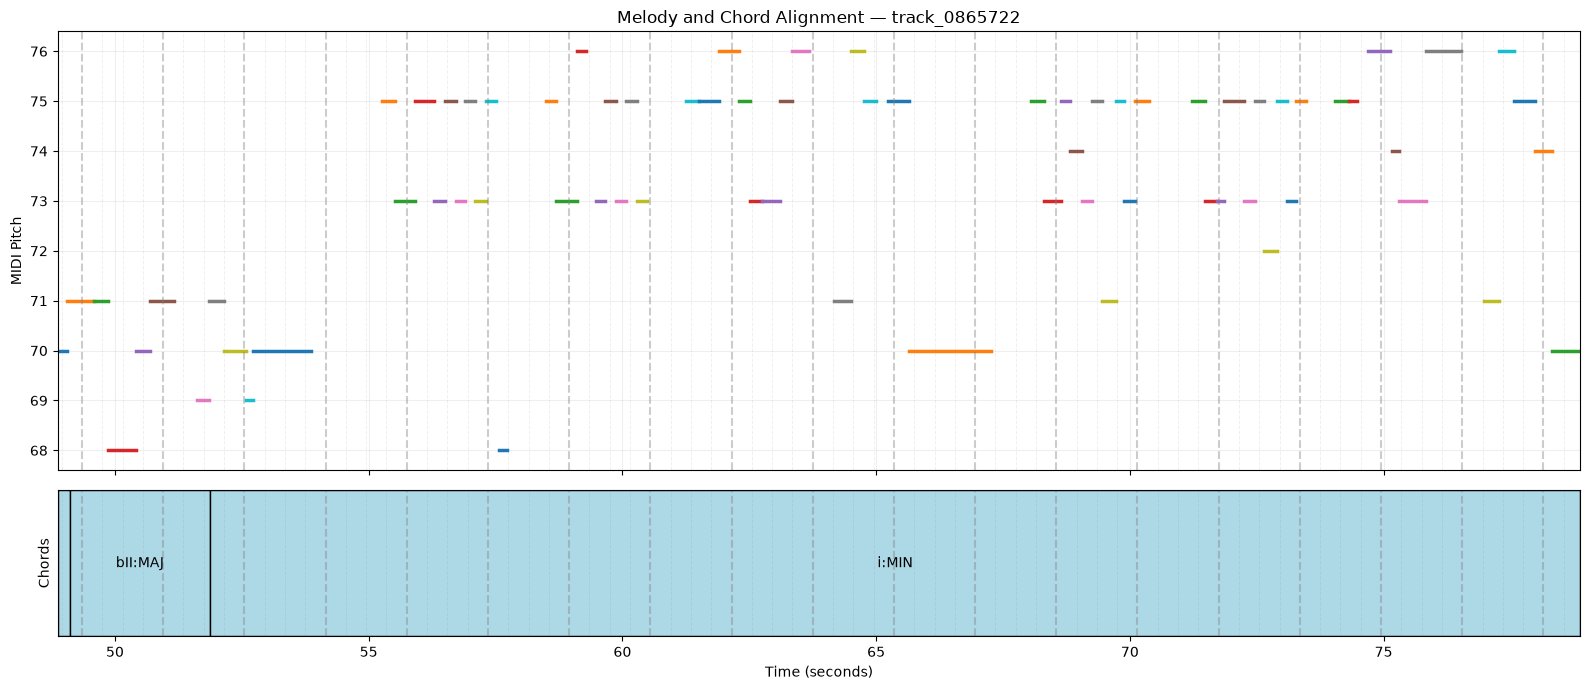

In [25]:
import json
import matplotlib.pyplot as plt


# -----------------------------------
# 1. Select a song
# -----------------------------------

TRACK_ID = "track_0865722"

folder = folder_lookup[TRACK_ID]


# -----------------------------------
# 2. Load extracted data
# -----------------------------------

with open(folder / REQUIRED_FILES["melody"]) as f:
    melody_data = json.load(f)

with open(folder / REQUIRED_FILES["beats"]) as f:
    beat_data = json.load(f)

with open(folder / REQUIRED_FILES["chords"]) as f:
    chord_data = json.load(f)


notes = melody_data["notes"]
beats = beat_data["beats"]
chords = chord_data["events"]


# -----------------------------------
# 3. Find the longest actual chord
# -----------------------------------

actual_chords = [
    chord for chord in chords
    if chord["basic_label"] != "N"
]

longest_chord = max(
    actual_chords,
    key=lambda c: c["end_sec"] - c["start_sec"]
)

print("TRACK:", TRACK_ID)

print(
    "Longest chord:",
    longest_chord["basic_label"]
)

print(
    "Chord duration:",
    round(
        longest_chord["end_sec"]
        - longest_chord["start_sec"],
        2
    ),
    "seconds"
)


# -----------------------------------
# 4. Select a 30-second section
# -----------------------------------

START_SEC = max(
    0,
    longest_chord["start_sec"] - 3
)

END_SEC = min(
    melody_data["duration_sec"],
    START_SEC + 30
)


# -----------------------------------
# 5. Create visualization
# -----------------------------------

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(16, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)


# -----------------------------------
# 6. Draw melody notes
# -----------------------------------

for note in notes:

    start = max(
        START_SEC,
        note["onset_sec"]
    )

    end = min(
        END_SEC,
        note["offset_sec"]
    )

    if start >= end:
        continue

    pitch = note["midi_pitch_rounded"]

    ax1.plot(
        [start, end],
        [pitch, pitch],
        linewidth=2.5
    )


ax1.set_ylabel("MIDI Pitch")
ax1.set_title(
    f"Melody and Chord Alignment — {TRACK_ID}"
)
ax1.grid(alpha=0.2)


# -----------------------------------
# 7. Draw chord intervals
# -----------------------------------

for chord in chords:

    start = max(
        START_SEC,
        chord["start_sec"]
    )

    end = min(
        END_SEC,
        chord["end_sec"]
    )

    if start >= end:
        continue

    ax2.broken_barh(
        [(start, end - start)],
        (0, 1),
        facecolors="lightblue",
        edgecolors="black"
    )

    # Display labels when there is enough space
    if end - start >= 1.5:

        ax2.text(
            (start + end) / 2,
            0.5,
            chord["basic_label"],
            ha="center",
            va="center",
            fontsize=10
        )


ax2.set_ylim(0, 1)
ax2.set_yticks([])
ax2.set_ylabel("Chords")


# -----------------------------------
# 8. Draw beat and downbeat markers
# -----------------------------------

for beat in beats:

    time = beat["time_sec"]

    if not START_SEC <= time <= END_SEC:
        continue

    for ax in (ax1, ax2):

        ax.axvline(
            time,
            color="gray",
            linestyle="--",
            alpha=0.4 if beat["is_downbeat"] else 0.12,
            linewidth=1.5 if beat["is_downbeat"] else 0.7
        )


# -----------------------------------
# 9. Finish
# -----------------------------------

ax2.set_xlabel("Time (seconds)")

ax1.set_xlim(START_SEC, END_SEC)

plt.tight_layout()
plt.show()

### Local Pitch Instability Analysis

In [26]:
import json
import numpy as np
import pandas as pd
from collections import Counter, defaultdict


# -----------------------------------
# 1. Configuration
# -----------------------------------

TRACK_ID = "track_0998080"

SECTION_SEC = 8.0

# Preliminary diagnostic thresholds
MAX_TIME_BETWEEN_ONSETS = 0.40
MAX_REST_BETWEEN_NOTES = 0.20
LARGE_JUMP_SEMITONES = 12


# -----------------------------------
# 2. Load melody
# -----------------------------------

folder = folder_lookup[TRACK_ID]

with open(folder / REQUIRED_FILES["melody"]) as f:
    melody_data = json.load(f)

notes = melody_data["notes"]
song_duration = melody_data["duration_sec"]


# -----------------------------------
# 3. Inspect note sources
# -----------------------------------

source_counts = Counter(
    str(note.get("source", "unknown"))
    for note in notes
)

print("MELODY SOURCE DISTRIBUTION")
print("--------------------------------")

print("Track:", TRACK_ID)
print("Total notes:", len(notes))

for source, count in source_counts.items():
    print(f"{source}: {count}")


# -----------------------------------
# 4. Group notes by source
# -----------------------------------

notes_by_source = defaultdict(list)

for note in notes:

    source = str(note.get("source", "unknown"))

    notes_by_source[source].append(note)


# -----------------------------------
# 5. Detect rapid pitch jumps
# -----------------------------------

transition_rows = []

for source, source_notes in notes_by_source.items():

    source_notes = sorted(
        source_notes,
        key=lambda n: n["onset_sec"]
    )

    for previous, current in zip(
        source_notes[:-1],
        source_notes[1:]
    ):

        onset_difference = (
            current["onset_sec"]
            - previous["onset_sec"]
        )

        rest_duration = (
            current["onset_sec"]
            - previous["offset_sec"]
        )

        # Compare only nearby, sequential notes.
        # Skip simultaneous notes and long gaps.
        if not (
            0 < onset_difference <= MAX_TIME_BETWEEN_ONSETS
            and -0.05 <= rest_duration <= MAX_REST_BETWEEN_NOTES
        ):
            continue

        pitch_difference = abs(
            current["midi_pitch_rounded"]
            - previous["midi_pitch_rounded"]
        )

        large_jump = (
            pitch_difference >= LARGE_JUMP_SEMITONES
        )

        transition_rows.append({
            "source": source,
            "time_sec": current["onset_sec"],
            "pitch_difference": pitch_difference,
            "large_jump": large_jump
        })


# -----------------------------------
# 6. Group results into sections
# -----------------------------------

transition_df = pd.DataFrame(transition_rows)

if not transition_df.empty:

    transition_df["section"] = (
        transition_df["time_sec"] // SECTION_SEC
    ).astype(int)

    section_stats = (
        transition_df.groupby(["section", "source"])
        .agg(
            transitions=("large_jump", "size"),
            large_jumps=("large_jump", "sum"),
            mean_pitch_change=(
                "pitch_difference", "mean"
            )
        )
        .reset_index()
    )

    section_stats["jump_rate"] = (
        section_stats["large_jumps"]
        / section_stats["transitions"]
    )

    section_stats["start_sec"] = (
        section_stats["section"] * SECTION_SEC
    )

    section_stats["end_sec"] = (
        section_stats["start_sec"] + SECTION_SEC
    )


    # -----------------------------------
    # 7. Display results
    # -----------------------------------

    print("\nPITCH INSTABILITY SUMMARY")
    print("--------------------------------")

    print(
        "Comparable note transitions:",
        len(transition_df)
    )

    print(
        "Rapid octave-or-larger jumps:",
        transition_df["large_jump"].sum()
    )


    print("\nSECTIONS WITH MOST RAPID LARGE JUMPS")
    print("--------------------------------")

    # Require several transitions so one jump
    # doesn't dominate a nearly empty section
    suspicious = section_stats[
        section_stats["transitions"] >= 5
    ]

    display(
        suspicious.sort_values(
            ["jump_rate", "large_jumps"],
            ascending=False
        ).head(20)
    )

else:

    print("No comparable note transitions found.")

MELODY SOURCE DISTRIBUTION
--------------------------------
Track: track_0998080
Total notes: 742
sheetsage2_instrumental: 322
game_vocal: 420

PITCH INSTABILITY SUMMARY
--------------------------------
Comparable note transitions: 576
Rapid octave-or-larger jumps: 20

SECTIONS WITH MOST RAPID LARGE JUMPS
--------------------------------


,section,source,transitions,large_jumps,mean_pitch_change,jump_rate,start_sec,end_sec
35,22,game_vocal,14,7,15.142857,0.500000,176.0,184.0
16,10,game_vocal,21,5,11.142857,0.238095,80.0,88.0
14,9,game_vocal,15,3,5.533333,0.200000,72.0,80.0
12,8,game_vocal,12,2,8.166667,0.166667,64.0,72.0
21,13,game_vocal,23,1,4.000000,0.043478,104.0,112.0
26,17,game_vocal,23,1,3.217391,0.043478,136.0,144.0
29,19,game_vocal,27,1,2.851852,0.037037,152.0,160.0
0,0,sheetsage2_instrumental,32,0,1.250000,0.000000,0.0,8.0
1,1,game_vocal,8,0,1.875000,0.000000,8.0,16.0
2,1,sheetsage2_instrumental,24,0,1.250000,0.000000,8.0,16.0


### Visualize Pitch Instability

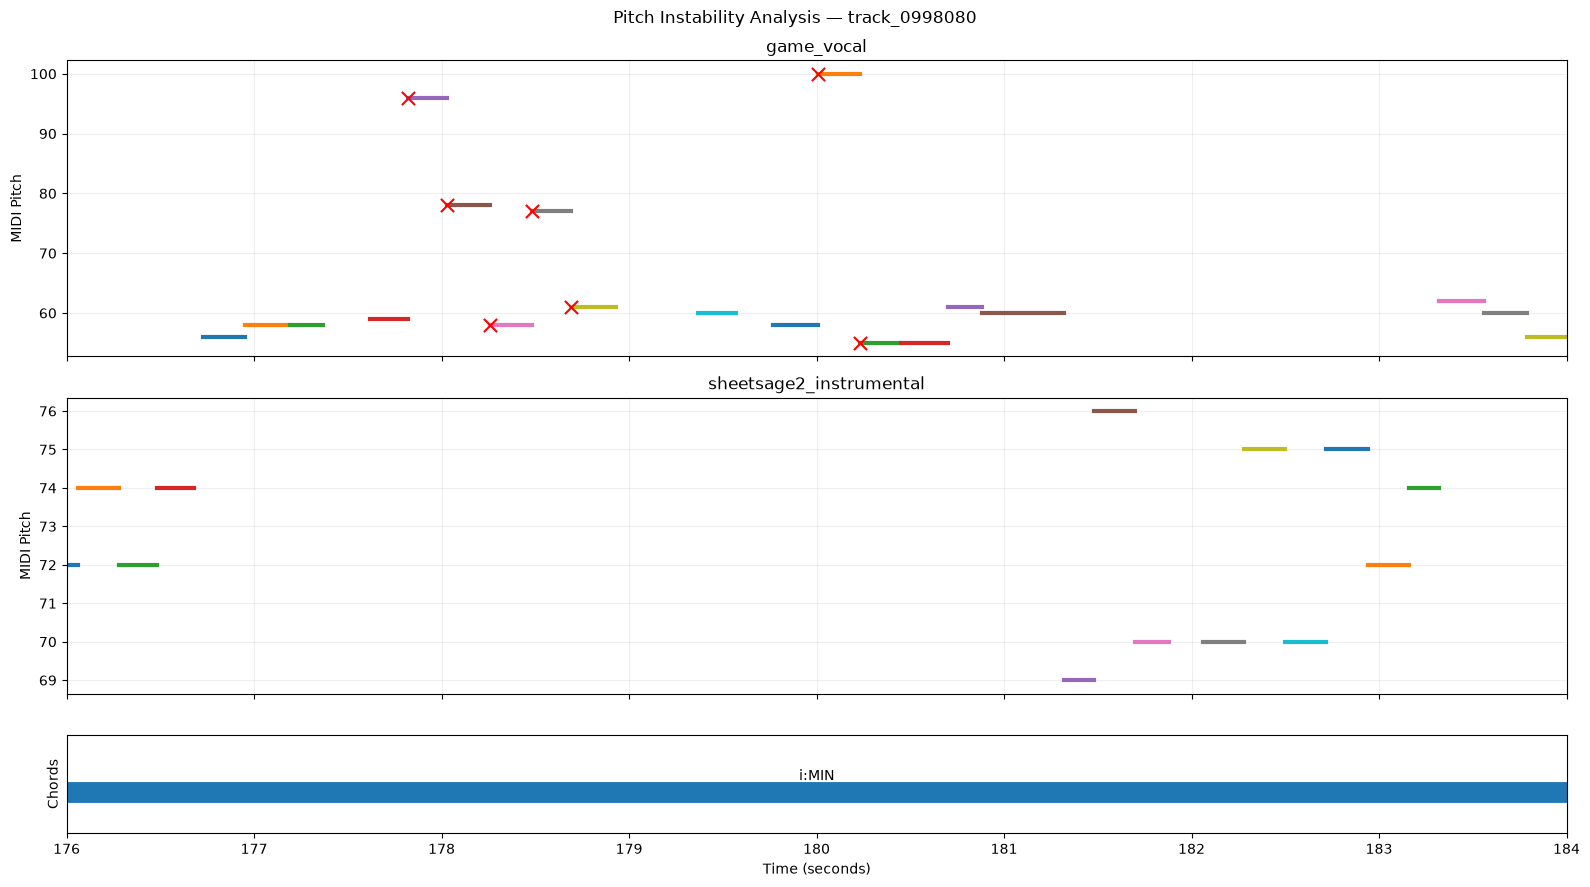

In [27]:
import json
import matplotlib.pyplot as plt
from collections import defaultdict


# -----------------------------------
# 1. Configuration
# -----------------------------------

TRACK_ID = "track_0998080"

START_SEC = 176
END_SEC = 184

folder = folder_lookup[TRACK_ID]


# -----------------------------------
# 2. Load melody and chord data
# -----------------------------------

with open(folder / REQUIRED_FILES["melody"]) as f:
    melody = json.load(f)

with open(folder / REQUIRED_FILES["chords"]) as f:
    chord_data = json.load(f)

notes = melody["notes"]
chords = chord_data["events"]


# -----------------------------------
# 3. Separate notes by source
# -----------------------------------

notes_by_source = defaultdict(list)

for note in notes:
    notes_by_source[note["source"]].append(note)


# -----------------------------------
# 4. Create visualization
# -----------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 3, 1]}
)

sources = [
    "game_vocal",
    "sheetsage2_instrumental"
]


# -----------------------------------
# 5. Draw melody notes and suspicious jumps
# -----------------------------------

for ax, source in zip(axes[:2], sources):

    source_notes = sorted(
        notes_by_source[source],
        key=lambda n: n["onset_sec"]
    )

    # Draw individual MIDI notes
    for note in source_notes:

        start = max(
            note["onset_sec"],
            START_SEC
        )

        end = min(
            note["offset_sec"],
            END_SEC
        )

        if start >= end:
            continue

        ax.plot(
            [start, end],
            [note["midi_pitch_rounded"]] * 2,
            linewidth=3
        )

    # Highlight rapid jumps
    for previous, current in zip(
        source_notes[:-1],
        source_notes[1:]
    ):

        onset_difference = (
            current["onset_sec"]
            - previous["onset_sec"]
        )

        rest_duration = (
            current["onset_sec"]
            - previous["offset_sec"]
        )

        pitch_difference = abs(
            current["midi_pitch_rounded"]
            - previous["midi_pitch_rounded"]
        )

        suspicious = (
            0 < onset_difference <= 0.40
            and -0.05 <= rest_duration <= 0.20
            and pitch_difference >= 12
        )

        if (
            suspicious
            and START_SEC <= current["onset_sec"] < END_SEC
        ):

            ax.scatter(
                current["onset_sec"],
                current["midi_pitch_rounded"],
                color="red",
                s=90,
                marker="x",
                zorder=5
            )

    ax.set_title(source)
    ax.set_ylabel("MIDI Pitch")
    ax.grid(alpha=0.2)


# -----------------------------------
# 6. Draw chord annotations
# -----------------------------------

ax_chords = axes[2]

for chord in chords:

    start = max(
        START_SEC,
        chord["start_sec"]
    )

    end = min(
        END_SEC,
        chord["end_sec"]
    )

    if start >= end:
        continue

    ax_chords.plot(
        [start, end],
        [0, 0],
        linewidth=15
    )

    ax_chords.text(
        (start + end) / 2,
        0.15,
        chord["basic_label"],
        ha="center"
    )

ax_chords.set_ylim(-0.5, 0.7)
ax_chords.set_yticks([])
ax_chords.set_ylabel("Chords")


# -----------------------------------
# 7. Finish
# -----------------------------------

axes[-1].set_xlabel("Time (seconds)")
axes[-1].set_xlim(START_SEC, END_SEC)

plt.suptitle(
    f"Pitch Instability Analysis — {TRACK_ID}"
)

plt.tight_layout()
plt.show()

### Isolated Pitch Spike Detection

In [28]:
import json
import pandas as pd


# -----------------------------------
# 1. Configuration
# -----------------------------------

TRACK_ID = "track_0998080"

SOURCE = "game_vocal"

MIN_JUMP = 9          # Semitones
MAX_RETURN_DIFF = 4   # Semitones
MAX_ONSET_GAP = 0.45  # Seconds


# -----------------------------------
# 2. Load vocal notes
# -----------------------------------

folder = folder_lookup[TRACK_ID]

with open(folder / REQUIRED_FILES["melody"]) as f:
    melody = json.load(f)

notes = sorted(
    [
        note for note in melody["notes"]
        if note["source"] == SOURCE
    ],
    key=lambda n: n["onset_sec"]
)


# -----------------------------------
# 3. Detect isolated pitch spikes
# -----------------------------------

spike_rows = []

for i in range(1, len(notes) - 1):

    previous = notes[i - 1]
    current = notes[i]
    following = notes[i + 1]

    p1 = previous["midi_pitch_rounded"]
    p2 = current["midi_pitch_rounded"]
    p3 = following["midi_pitch_rounded"]

    # Time between neighboring note onsets
    gap1 = current["onset_sec"] - previous["onset_sec"]
    gap2 = following["onset_sec"] - current["onset_sec"]

    # Avoid unrelated notes or overlapping passages
    rest1 = current["onset_sec"] - previous["offset_sec"]
    rest2 = following["onset_sec"] - current["offset_sec"]

    if not (
        0 < gap1 <= MAX_ONSET_GAP
        and 0 < gap2 <= MAX_ONSET_GAP
        and -0.05 <= rest1 <= 0.20
        and -0.05 <= rest2 <= 0.20
    ):
        continue

    # Pitch movement
    jump_in = abs(p2 - p1)
    jump_out = abs(p3 - p2)

    # Difference between surrounding notes
    return_difference = abs(p3 - p1)

    # Large movement followed by a return
    is_spike = (
        jump_in >= MIN_JUMP
        and jump_out >= MIN_JUMP
        and return_difference <= MAX_RETURN_DIFF
    )

    if is_spike:

        spike_rows.append({
            "time_sec": current["onset_sec"],
            "previous_pitch": p1,
            "suspected_pitch": p2,
            "following_pitch": p3,
            "jump_in": jump_in,
            "jump_out": jump_out,
            "return_difference": return_difference,
            "section": int(
                current["onset_sec"] // 8
            )
        })


# -----------------------------------
# 4. Display results
# -----------------------------------

spike_df = pd.DataFrame(spike_rows)

print("ISOLATED PITCH SPIKE ANALYSIS")
print("--------------------------------")

print("Track:", TRACK_ID)
print("Source:", SOURCE)
print("Notes analyzed:", len(notes))
print("Suspected isolated spikes:", len(spike_df))


if not spike_df.empty:

    print("\nSUSPECTED SPIKES")
    print("--------------------------------")

    display(spike_df)

    print("\nSPIKES BY 8-SECOND SECTION")
    print("--------------------------------")

    section_counts = (
        spike_df.groupby("section")
        .size()
        .reset_index(name="spikes")
    )

    section_counts["start_sec"] = (
        section_counts["section"] * 8
    )

    section_counts["end_sec"] = (
        section_counts["start_sec"] + 8
    )

    display(
        section_counts.sort_values(
            "spikes",
            ascending=False
        )
    )

ISOLATED PITCH SPIKE ANALYSIS
--------------------------------
Track: track_0998080
Source: game_vocal
Notes analyzed: 420
Suspected isolated spikes: 4

SUSPECTED SPIKES
--------------------------------


,time_sec,previous_pitch,suspected_pitch,following_pitch,jump_in,jump_out,return_difference,section
0,139.47,59,68,56,9,12,3,17
1,178.26,78,58,77,20,19,1,22
2,178.48,58,77,61,19,16,3,22
3,180.01,58,100,55,42,45,3,22



SPIKES BY 8-SECOND SECTION
--------------------------------


,section,spikes,start_sec,end_sec
1,22,3,176,184
0,17,1,136,144


### Analyze Melody–Chord Compatibility

In [29]:
import json
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Configuration
# -----------------------------------

TRACK_ID = "track_0998080"

SECTIONS = [
    (40, 48),
    (64, 72),
    (72, 80),
    (80, 88),
    (176, 184)
]


# -----------------------------------
# 2. Chord-family pitch intervals
# -----------------------------------

CHORD_INTERVALS = {
    "MAJ":   {0, 4, 7},
    "MIN":   {0, 3, 7},
    "DOM7":  {0, 4, 7, 10},
    "DIM":   {0, 3, 6},
    "DIM7":  {0, 3, 6, 9},
    "HDIM7": {0, 3, 6, 10},
    "AUG":   {0, 4, 8},
    "SUS4":  {0, 5, 7}
}


# -----------------------------------
# 3. Load song information
# -----------------------------------

folder = folder_lookup[TRACK_ID]

with open(folder / REQUIRED_FILES["melody"]) as f:
    melody = json.load(f)

with open(folder / REQUIRED_FILES["chords"]) as f:
    chord_data = json.load(f)

with open(folder / REQUIRED_FILES["key"]) as f:
    key_data = json.load(f)


notes = melody["notes"]
chords = chord_data["events"]

selected_key = key_data["melody_key"]["selected"]

tonic_pc = selected_key["tonic_pc"]
mode = selected_key["mode"]


# -----------------------------------
# 4. Construct key-compatible pitch classes
# -----------------------------------

if mode == "major":

    scale_intervals = {0, 2, 4, 5, 7, 9, 11}

else:

    # Natural minor plus raised seventh,
    # which commonly occurs in minor-key music
    scale_intervals = {0, 2, 3, 5, 7, 8, 10, 11}


scale_pcs = {
    (tonic_pc + interval) % 12
    for interval in scale_intervals
}


print("MELODY–CHORD COMPATIBILITY")
print("--------------------------------")

print("Track:", TRACK_ID)
print("Estimated key:", selected_key)


# -----------------------------------
# 5. Analyze sections separately
# -----------------------------------

rows = []

sources = sorted({
    note["source"]
    for note in notes
})

for section_start, section_end in SECTIONS:

    for source in sources:

        durations = Counter()
        note_count = 0

        for note in notes:

            if note["source"] != source:
                continue

            # Clip note to section
            note_start = max(
                note["onset_sec"],
                section_start
            )

            note_end = min(
                note["offset_sec"],
                section_end
            )

            if note_start >= note_end:
                continue

            note_count += 1

            pitch_pc = (
                note["midi_pitch_rounded"] % 12
            )

            # Compare note against overlapping chords
            for chord in chords:

                family = chord.get("family")

                root_relative = chord.get(
                    "relative_root_semitones"
                )

                if (
                    family not in CHORD_INTERVALS
                    or root_relative is None
                ):
                    continue

                overlap = max(
                    0,
                    min(note_end, chord["end_sec"])
                    - max(note_start, chord["start_sec"])
                )

                if overlap <= 0:
                    continue

                # Absolute chord root
                root_pc = (
                    tonic_pc + int(root_relative)
                ) % 12

                # Chord pitch classes
                chord_pcs = {
                    (root_pc + interval) % 12
                    for interval in CHORD_INTERVALS[family]
                }

                # Classify the note
                if pitch_pc in chord_pcs:

                    category = "chord_tone"

                elif pitch_pc in scale_pcs:

                    category = "key_compatible"

                else:

                    category = "other_pitch"

                durations[category] += overlap

        # -----------------------------------
        # 6. Calculate percentages
        # -----------------------------------

        total = sum(durations.values())

        def percentage(value):
            return (
                100 * value / total
                if total > 0 else float("nan")
            )

        rows.append({
            "start_sec": section_start,
            "end_sec": section_end,
            "source": source,
            "notes": note_count,

            "chord_tone_%": percentage(
                durations["chord_tone"]
            ),

            "key_compatible_%": percentage(
                durations["key_compatible"]
            ),

            "other_pitch_%": percentage(
                durations["other_pitch"]
            ),

            "analyzed_note_seconds": total
        })


# -----------------------------------
# 7. Display results
# -----------------------------------

compatibility_df = pd.DataFrame(rows)

print("\nSECTION COMPATIBILITY RESULTS")
print("--------------------------------")

display(
    compatibility_df.round(2)
)

MELODY–CHORD COMPATIBILITY
--------------------------------
Track: track_0998080
Estimated key: {'tonic': 'A', 'tonic_pc': 9, 'mode': 'minor', 'confidence': 'high'}

SECTION COMPATIBILITY RESULTS
--------------------------------


,start_sec,end_sec,source,notes,chord_tone_%,key_compatible_%,other_pitch_%,analyzed_note_seconds
0,40,48,game_vocal,26,0.00,70.05,29.95,5.71
1,40,48,sheetsage2_instrumental,0,NaN,NaN,NaN,0.00
2,64,72,game_vocal,15,23.20,46.93,29.87,3.75
3,64,72,sheetsage2_instrumental,16,78.09,0.00,21.91,3.47
4,72,80,game_vocal,19,16.35,40.87,42.79,4.16
5,72,80,sheetsage2_instrumental,12,15.95,15.93,68.12,2.76
6,80,88,game_vocal,24,15.65,57.04,27.30,5.75
7,80,88,sheetsage2_instrumental,8,27.62,27.62,44.76,1.81
8,176,184,game_vocal,19,29.68,35.39,34.93,4.38
9,176,184,sheetsage2_instrumental,13,34.38,23.21,42.41,2.50


### Final Dataset Preparation

In [30]:
import pandas as pd


# -----------------------------------
# 1. Start with usable windows
# -----------------------------------

dataset_windows = candidates.copy()


# -----------------------------------
# 2. Attach melody quality information
# -----------------------------------

melody_info = window_df[
    [
        "track_id",
        "start_sec",
        "end_sec",
        "note_count",
        "coverage",
        "longest_gap"
    ]
].copy()

dataset_windows = dataset_windows.merge(
    melody_info,
    on=["track_id", "start_sec", "end_sec"],
    how="left",
    validate="one_to_one"
)


# -----------------------------------
# 3. Attach song metadata
# -----------------------------------

song_metadata = genre_df[
    [
        "mtg_track_id",
        "artist_id",
        "split_0",
        "genres",
        "selected_genres"
    ]
].rename(
    columns={"mtg_track_id": "track_id"}
)

dataset_windows = dataset_windows.merge(
    song_metadata,
    on="track_id",
    how="left",
    validate="many_to_one"
)


# -----------------------------------
# 4. Attach key information
# -----------------------------------

key_info = key_df[
    [
        "track_id",
        "melody_tonic_pc",
        "melody_mode",
        "melody_confidence"
    ]
]

dataset_windows = dataset_windows.merge(
    key_info,
    on="track_id",
    how="left",
    validate="many_to_one"
)


# -----------------------------------
# 5. Identify genre-eligible windows
# -----------------------------------

dataset_windows["genre_eligible"] = (
    dataset_windows["selected_genres"].apply(
        lambda genres: (
            isinstance(genres, list)
            and len(genres) > 0
        )
    )
)


# -----------------------------------
# 6. Validate dataset integrity
# -----------------------------------

assert dataset_windows["track_id"].notna().all()

assert dataset_windows["artist_id"].notna().all()

assert dataset_windows["split_0"].isin(
    ["train", "validation", "test"]
).all()

assert dataset_windows["melody_mode"].isin(
    ["major", "minor"]
).all()

assert dataset_windows["coverage"].notna().all()

assert not dataset_windows.duplicated(
    ["track_id", "start_sec", "end_sec"]
).any()

# Confirm artists do not cross splits
artist_splits = (
    dataset_windows.groupby("artist_id")["split_0"]
    .nunique()
)

assert (artist_splits == 1).all()


# -----------------------------------
# 7. Dataset summary
# -----------------------------------

print("PHASE 2 — PREPARED DATASET")
print("--------------------------------")

print("Total windows:", len(dataset_windows))

print(
    "Unique songs:",
    dataset_windows["track_id"].nunique()
)

print(
    "Unique artists:",
    dataset_windows["artist_id"].nunique()
)

print(
    "Genre-eligible windows:",
    dataset_windows["genre_eligible"].sum()
)


# -----------------------------------
# 8. Distribution across splits
# -----------------------------------

print("\nDATASET SPLITS")
print("--------------------------------")

split_stats = (
    dataset_windows.groupby("split_0")
    .agg(
        windows=("track_id", "size"),
        songs=("track_id", "nunique"),
        artists=("artist_id", "nunique"),
        genre_windows=("genre_eligible", "sum")
    )
)

display(split_stats)


# -----------------------------------
# 9. Preview training windows
# -----------------------------------

print("\nDATASET PREVIEW")
print("--------------------------------")

display(
    dataset_windows[
        [
            "track_id",
            "start_sec",
            "end_sec",
            "note_count",
            "coverage",
            "chord_coverage",
            "melody_mode",
            "selected_genres",
            "split_0"
        ]
    ].head(10)
)

PHASE 2 — PREPARED DATASET
--------------------------------
Total windows: 2845
Unique songs: 238
Unique artists: 81
Genre-eligible windows: 2156

DATASET SPLITS
--------------------------------


,windows,songs,artists,genre_windows
split_0,,,,
test,772,55,19,608
train,1525,126,48,1280
validation,548,57,14,268



DATASET PREVIEW
--------------------------------


,track_id,start_sec,end_sec,note_count,coverage,chord_coverage,melody_mode,selected_genres,split_0
0,track_0000390,1.97,22.02,18,0.877805,1.000000,major,[],train
1,track_0000390,22.86,42.61,20,0.902278,0.895696,major,[],train
2,track_0000390,42.61,62.53,18,0.700301,1.000000,major,[],train
3,track_0000390,62.53,81.21,19,0.822805,1.000000,major,[],train
4,track_0000390,81.21,99.89,13,0.670771,1.000000,major,[],train
5,track_0000390,99.89,117.61,17,0.902370,1.000000,major,[],train
6,track_0000391,35.17,51.41,25,0.886084,1.000000,minor,[],train
7,track_0000391,51.41,66.37,27,0.894385,0.828209,minor,[],train
8,track_0000391,66.37,79.81,15,0.796131,0.880208,minor,[],train
9,track_0000394,22.29,44.01,19,0.969613,0.924954,major,[],train


In [31]:
display(
    dataset_windows[
        [
            "track_id",
            "genres",
            "selected_genres",
            "genre_eligible"
        ]
    ].head(20)
)

,track_id,genres,selected_genres,genre_eligible
0,track_0000390,[classical],[],False
1,track_0000390,[classical],[],False
2,track_0000390,[classical],[],False
3,track_0000390,[classical],[],False
4,track_0000390,[classical],[],False
5,track_0000390,[classical],[],False
6,track_0000391,[classical],[],False
7,track_0000391,[classical],[],False
8,track_0000391,[classical],[],False
9,track_0000394,[classical],[],False


### Save Phase 2 Dataset Snapshot

In [32]:
from pathlib import Path
import json
import shutil
import hashlib
import pandas as pd
from datetime import datetime, timezone


# -----------------------------------
# 1. Configure snapshot location
# -----------------------------------

SNAPSHOT_DIR = (
    Path.cwd() / "phase2_dataset_v1"
)

# Never overwrite an existing snapshot
if SNAPSHOT_DIR.exists():
    raise FileExistsError(
        f"Snapshot already exists: {SNAPSHOT_DIR}"
    )

SNAPSHOT_DIR.mkdir(parents=True)


# -----------------------------------
# 2. Save window metadata
# -----------------------------------

snapshot_windows = (
    dataset_windows
    .sort_values(["track_id", "start_sec"])
    .reset_index(drop=True)
)

WINDOW_FILE = SNAPSHOT_DIR / "windows.jsonl"

snapshot_windows.to_json(
    WINDOW_FILE,
    orient="records",
    lines=True,
    double_precision=15
)


# -----------------------------------
# 3. Copy extracted JSON files
# -----------------------------------

TRACKS_DIR = SNAPSHOT_DIR / "tracks"

file_hashes = {}

track_ids = sorted(
    snapshot_windows["track_id"].unique()
)

for track_id in track_ids:

    source_folder = folder_lookup[track_id]

    destination_folder = (
        TRACKS_DIR / track_id
    )

    for relative_path in REQUIRED_FILES.values():

        source_file = (
            source_folder / relative_path
        )

        destination_file = (
            destination_folder / relative_path
        )

        destination_file.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        # Copy original JSON
        shutil.copy2(
            source_file,
            destination_file
        )

        # Verify copied file matches original
        source_hash = hashlib.sha256(
            source_file.read_bytes()
        ).hexdigest()

        copied_hash = hashlib.sha256(
            destination_file.read_bytes()
        ).hexdigest()

        assert source_hash == copied_hash, (
            f"File changed during copying: {source_file}"
        )

        file_hashes[
            f"{track_id}/{relative_path}"
        ] = copied_hash


# -----------------------------------
# 4. Save snapshot configuration
# -----------------------------------

snapshot_config = {
    "version": "phase2_dataset_v1",

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "songs": len(track_ids),

    "windows": len(snapshot_windows),

    "genres": TOP_GENRES,

    "window_bars": 8,

    "filtering": {
        "key_agreement": "agree",
        "melody_key_confidence": "high",
        "chord_key_confidence": "high",
        "minimum_melody_coverage": 0.50,
        "minimum_melody_notes": 10,
        "maximum_melody_gap_sec": 8,
        "minimum_chord_coverage": 0.80
    },

    "file_sha256": file_hashes
}

with open(
    SNAPSHOT_DIR / "config.json",
    "w"
) as f:

    json.dump(
        snapshot_config,
        f,
        indent=2
    )


# -----------------------------------
# 5. Verify saved dataset
# -----------------------------------

loaded_windows = pd.read_json(
    WINDOW_FILE,
    orient="records",
    lines=True
)

assert len(loaded_windows) == len(snapshot_windows)

assert (
    loaded_windows["track_id"].nunique()
    == len(track_ids)
)

assert not loaded_windows.duplicated(
    ["track_id", "start_sec", "end_sec"]
).any()


# -----------------------------------
# 6. Display snapshot summary
# -----------------------------------

print("PHASE 2 DATASET SNAPSHOT")
print("--------------------------------")

print("Location:", SNAPSHOT_DIR)

print("Songs:", len(track_ids))

print("Windows:", len(loaded_windows))

print(
    "Artists:",
    loaded_windows["artist_id"].nunique()
)

print(
    "Genre-eligible windows:",
    loaded_windows["genre_eligible"].sum()
)

print(
    "JSON files saved:",
    len(file_hashes)
)

print("\nSnapshot saved successfully!")

PHASE 2 DATASET SNAPSHOT
--------------------------------
Location: /Users/praise/Developer/vocal-harmonization/experiments/pasan/notebooks/phase2_dataset_v1
Songs: 238
Windows: 2845
Artists: 81
Genre-eligible windows: 2156
JSON files saved: 952

Snapshot saved successfully!
